<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 0. CONFIG 

 </div>

In [3]:
# %%
# ── 0. CONFIG — new pilot ──
import sys, os
import numpy as np
import pandas as pd
import importlib
import lfp_main as lfm
importlib.reload(lfm)                           # picks up changes to lfp_main.py without restarting

SESSION   = "20260529_r0000136_wt_1318"      # main pilot (rat 136, both references clean)
# SESSION = "20260529_r0000135_wt_1411"      # second pilot (rat 135, CMR only)


DATA_ROOT   = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
SESSION_DIR = os.path.join(DATA_ROOT, "2_processed", SESSION)
REC_ORIG    = os.path.join(SESSION_DIR, "amir_data", "down_sampled", "1000_Hz")
TABLES      = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main\tables"
OUT_DIR     = os.path.join(SESSION_DIR, "amir_data", "pilot")          # all pilot outputs of this session
os.makedirs(OUT_DIR, exist_ok=True)

MAIN = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main"
sys.path.insert(0, MAIN)
import tfr_functions_pilot as tfx               # frozen
sys.modules["tfr_functions"] = tfx              # tfr_stats_pilot.py imports it under the old name
import tfr_stats_pilot as tfs                   # frozen

# ── trial selection (rules R1–R4 are already in all_trials.csv → keep) ──
BLOCK_LONG_PROB     = 0.5                      # block rule: main comparisons only in 0.5 blocks
EARLY_LONG_MIN_HOLD = 0.3                      # Q2 long: early long only with hold > 0.3 s
N_SEL_TOTAL = 20    
#EXTRA_BAD = ["imec0.ap#AP362",     # QC: ~3.6x weaker power than its neighbours
             #"imec0.ap#AP381"]     # event check: CMR ERP ~4-5x larger than its neighbours in all 3 events                  
EXTRA_BAD = [] 

# ── extraction ──
TMIN, TMAX      = -3, 5
BASELINE_WINDOW = (-0.5, -0.2)                 # common pre-press baseline
CROP_WINDOW     = (-0.6, 2.0)
CROP_TONE       = (-1.2, 1.0)
CROP_RELEASE    = (-1.2, 1.0)

BAND_SETTINGS = [
    {"freqs": np.arange(1,   4, 1), "n_cycles": 2},
    {"freqs": np.arange(4,   8, 1), "n_cycles": 5},
    {"freqs": np.arange(8,  13, 1), "n_cycles": 6},
    {"freqs": np.arange(13, 30, 1), "n_cycles": 7},
    {"freqs": np.arange(30, 61, 1), "n_cycles": 10},
    {"freqs": np.arange(61,101, 1), "n_cycles": 10},
]
BAND_RANGES = {"delta": (1, 3), "theta": (4, 7), "alpha": (8, 12),
               "beta": (13, 29), "low_gamma": (30, 60), "high_gamma": (61, 100)}

# column names the frozen functions expect; in section 1 they are filled with the TTL-anchored times
EVENTS = {"Press": "press_np_s", "Tone": "tone_np_s", "Release": "release_np_s"}
BASELINE_EVENT = "Press"
CONDITIONS = [("correct", "long"), ("correct", "short"),
              ("early",   "long"), ("early",   "short"),
              ("late",    "long"), ("late",    "short")]
ALIGNMENTS = {
    "Press":   {"event": {"Press":   EVENTS["Press"]},   "crop": CROP_WINDOW},
    "Tone":    {"event": {"Tone":    EVENTS["Tone"]},    "crop": CROP_TONE},
    "Release": {"event": {"Release": EVENTS["Release"]}, "crop": CROP_RELEASE},
}

# ── display ──
OSCILLATION_BOUNDARIES = [4, 8, 13, 30, 61]
FULL_FREQ_RANGE = (1, 99)
FULL_YTICKS     = [1, 4, 8, 13, 20, 30, 40, 50, 60, 70, 80, 90, 99]
ZOOM_FREQ_RANGE = (1, 15)
ZOOM_YTICKS     = list(range(1, 16))
VMAX, ZOOM_VMAX = 0.5, 0.5
PCT_VMAX        = 100                          # one colour scale for all % change plots
TONE_DELAY      = {"short": 0.35, "long": 1.05}

# ── permutation settings ──
N_PERMUTATIONS = 5000
SEED  = 0
DECIM = 10
STAT_BANDS = {"Delta": (1, 3), "Theta + alpha": (4, 12), "Beta": (13, 29),
              "Low gamma": (30, 60), "High gamma": (61, 100)}
STAT_BAND_COLORS = {"Delta": "#4C72B0", "Theta + alpha": "#DD8452", "Beta": "#55A868",
                    "Low gamma": "#C44E52", "High gamma": "#8172B3"}
CE_LONG_TESTS = {
    "Press":   {"window": (-0.3, 0.3),  "allow_pre": True},
    "Release": {"window": (-0.05, 0.5), "cross_release": True},
}
STAT_DIR = os.path.join(OUT_DIR, "cluster_based_permutation_test")

# ── CONFIG dict for functions that expect it ──
CONFIG = {
    "recording_path": REC_ORIG, "session_dir": SESSION_DIR, "behavior_csv": r"\share\trials.csv",
    "channel_id": None,                        # set in section 2 (first selected channel)
    "outcome": "correct", "trial_type": "long", "baseline_conditions": None,
    "events": EVENTS, "baseline_event": BASELINE_EVENT,
    "tmin": TMIN, "tmax": TMAX, "baseline_window": BASELINE_WINDOW, "crop_window": CROP_WINDOW,
    "band_settings": BAND_SETTINGS, "band": "alpha", "band_ranges": BAND_RANGES,
    "oscillation_boundaries": OSCILLATION_BOUNDARIES,
    "full_freq_range": FULL_FREQ_RANGE, "full_yticks": FULL_YTICKS,
    "zoom_freq_range": ZOOM_FREQ_RANGE, "zoom_yticks": ZOOM_YTICKS,
    "vmax": VMAX, "zoom_vmax": ZOOM_VMAX, "analysis_label": "raw",
    "save": True, "save_dir": os.path.join(OUT_DIR, "TFR", "raw"),
}
print("pilot session:", SESSION)

pilot session: 20260529_r0000136_wt_1318


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 1.Trials
 </div>

In [4]:
# %%
# ── 1. TRIALS: all_trials.csv → this session, keep == True, long_prob 0.5 ──
T = pd.read_csv(os.path.join(TABLES, "all_trials.csv"), dtype={"rat": str})
T = T[T["session"] == SESSION].set_index("trial")
raw = pd.read_csv(os.path.join(SESSION_DIR, "share", "trials.csv"))
assert len(raw) == len(T), "trial count differs between trials.csv and all_trials.csv"

beh = pd.DataFrame(index=T.index)
for c in ["press", "release", "tone"]:                 # behaviour clock, used only for intervals
    beh[c] = raw[c].values
for o in ["correct", "early", "late"]:                  # our labels (touch already separated)
    beh[o] = (T["outcome"] == o).astype(int)
beh["is_touch"] = (T["outcome"] == "touch").astype(int)
beh["long"]  = (T["type"] == "long").astype(int)       # from wt, not from the 'long' column
beh["short"] = (T["type"] == "short").astype(int)
# names expected by the frozen functions, filled with TTL-anchored neural times
beh["press_np_s"]   = T["press_neural_s"]
beh["tone_np_s"]    = T["tone_neural_s"]
beh["release_np_s"] = T["release_neural_s"]
for c in ["keep", "long_prob", "outcome", "type", "hold_s", "rt_s", "prev_outcome", "timing_mismatch"]:
    beh[c] = T[c]

beh_session = beh.copy()                                # all trials of the session (info only)
beh = beh[beh["keep"] & (beh["long_prob"] == BLOCK_LONG_PROB)]
all_trials = beh                                        # baseline pool = same trials as the comparisons
groups = tfs.build_groups(beh, early_long_min_hold=EARLY_LONG_MIN_HOLD)

print(f"session trials: {len(beh_session)} | kept: {int(beh_session['keep'].sum())} | "
      f"kept in long_prob {BLOCK_LONG_PROB} blocks: {len(beh)}")
for key in [("correct", "long"), ("correct", "short"), ("early", "long"), ("early", "long-filtered"),
            ("early", "short"), ("late", "long"), ("late", "short")]:
    if key in groups:
        print(f"  {tfs.group_label(key):25s}: {len(groups[key]):4d} trials")
print("timing_mismatch in these trials (flag only):", int(beh["timing_mismatch"].sum()))

session trials: 164 | kept: 142 | kept in long_prob 0.5 blocks: 142
  correct / long           :   49 trials
  correct / short          :   48 trials
  early / long             :   18 trials
  early / long-filtered    :   16 trials
  early / short            :    2 trials
  late / long              :    3 trials
  late / short             :   22 trials
timing_mismatch in these trials (flag only): 1


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 2. LFP + probe + channel selection

 </div>

In [5]:
# %%
# ── 2. LFP (original + CMR on the fly) + probe + 20 channels ──
import spikeinterface.preprocessing as spre

ds_orig = tfx.load_recording(REC_ORIG)
if EXTRA_BAD:
    ds_orig = ds_orig.remove_channels(EXTRA_BAD)                                   # BEFORE the CMR
ds_cmr  = spre.common_reference(ds_orig, reference="global", operator="median")   # CMR = main reference
fs = int(ds_orig.get_sampling_frequency())
recordings = {"original": ds_orig, "CMR": ds_cmr}
print(f"Sampling rate: {fs} Hz | channels: {ds_orig.get_num_channels()} "
      f"(extra bad removed: {EXTRA_BAD}) | duration: {ds_orig.get_total_duration() / 60:.1f} min")

# save the extra bad channels of this session (one table for all sessions)
eb_path = os.path.join(TABLES, "extra_bad_channels.csv")
eb = pd.read_csv(eb_path) if os.path.exists(eb_path) else pd.DataFrame(columns=["session", "channel_id", "reason"])
eb = eb[eb["session"] != SESSION]
eb = pd.concat([eb, pd.DataFrame({"session": SESSION, "channel_id": EXTRA_BAD,
                                  "reason": "signal QC: local outlier (power vs neighbours)"})])
eb.to_csv(eb_path, index=False)

# probe table from the recording's OWN channels (always matches the channels that are really there)
probe_df = pd.DataFrame(ds_orig.get_channel_locations(), columns=["x", "y"])
probe_df["channel_id"] = list(ds_orig.get_channel_ids())
probe_df["shank"] = (probe_df["x"] // 250).astype(int)          # NP2013: shanks at x = 0 / 250 / 500 / 750 µm
assert len(probe_df) == ds_orig.get_num_channels()

# 20 channels, spread over the shanks in proportion to their number of channels (at least 2 per shank)
N_SEL_TOTAL = 20
counts = probe_df["shank"].value_counts().sort_index()
n_per = (counts / counts.sum() * N_SEL_TOTAL).round().astype(int).clip(lower=2)
SELECTED_CHANNELS = []
for sh, d in probe_df.sort_values("y").groupby("shank"):
    idx = np.linspace(0, len(d) - 1, n_per[sh]).round().astype(int)
    SELECTED_CHANNELS += d.iloc[idx]["channel_id"].tolist()
selected_df = probe_df[probe_df["channel_id"].isin(SELECTED_CHANNELS)].reset_index(drop=True)
CONFIG["channel_id"] = SELECTED_CHANNELS[0]

print(f"Probe: {len(probe_df)} contacts, {probe_df['shank'].nunique()} shanks, {len(selected_df)} selected")
print("selected per shank:", n_per.to_dict(), "| AP362 in probe_df:", "imec0.ap#AP362" in probe_df["channel_id"].values)
print(selected_df.sort_values(["shank", "y"])[["channel_id", "shank", "x", "y"]].to_string(index=False))

Sampling rate: 1000 Hz | channels: 383 (extra bad removed: []) | duration: 32.1 min
Probe: 383 contacts, 3 shanks, 20 selected
selected per shank: {0: 6, 1: 10, 2: 4} | AP362 in probe_df: True
    channel_id  shank     x      y
imec0.ap#AP257      0  32.0 1560.0
imec0.ap#AP353      0  32.0 1920.0
imec0.ap#AP159      0  32.0 2625.0
 imec0.ap#AP15      0  32.0 2985.0
imec0.ap#AP109      0  32.0 3330.0
imec0.ap#AP205      0  32.0 3690.0
 imec0.ap#AP49      1 282.0    0.0
 imec0.ap#AP91      1 282.0  315.0
imec0.ap#AP240      1 250.0  720.0
imec0.ap#AP282      1 250.0 1035.0
imec0.ap#AP289      1 282.0 1800.0
imec0.ap#AP324      1 250.0 2070.0
 imec0.ap#AP30      1 250.0 2385.0
imec0.ap#AP120      1 250.0 2700.0
 imec0.ap#AP66      1 250.0 3015.0
imec0.ap#AP156      1 250.0 3330.0
imec0.ap#AP241      2 532.0 2160.0
imec0.ap#AP372      2 500.0 2790.0
imec0.ap#AP232      2 500.0 3180.0
imec0.ap#AP335      2 532.0 3585.0


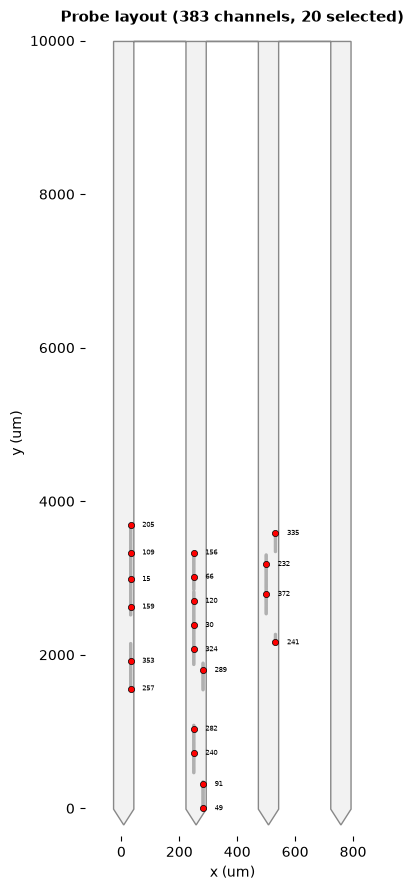

In [6]:
# %%
# ── probe layout, whole probe (same style) ──
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

fig, ax = plt.subplots(figsize=(4, 9))

# ── draw shank outlines from probeinterface ──
probe = ds_orig.get_probe()
contour = probe.probe_planar_contour
ax.add_patch(Polygon(contour, closed=True, facecolor="#f2f2f2",
                     edgecolor="#888888", linewidth=1.0, zorder=0))

# ── contacts ──
ax.scatter(probe_df["x"], probe_df["y"], s=6, c="#b0b0b0", edgecolors="none", zorder=2)

for _, row in selected_df.iterrows():
    ax.scatter(row["x"], row["y"], s=20, c="red", edgecolors="black",
               linewidths=0.5, zorder=5)
    ax.text(row["x"] + 40, row["y"], row["channel_id"].split("AP")[-1], fontsize=5, va="center")

ax.set_xlabel("x (um)")
ax.set_ylabel("y (um)")
ax.set_ylim(contour[:, 1].min() - 150, contour[:, 1].max() + 150)     # whole probe, tip to top
ax.set_xlim(contour[:, 0].min() - 100, contour[:, 0].max() + 100)     # all 4 shanks
ax.set_title(f"Probe layout ({len(probe_df)} channels, {len(selected_df)} selected)",
             fontsize=11, fontweight="bold")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "probe_layout_whole_probe.png"), dpi=200, bbox_inches="tight")
plt.show()


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 3. Signal QC (original and CMR)
- PSD per channel (Welch, 30 × 10 s pieces spread over the whole recording, 1–100 Hz)
- Single bad channels: each channel vs its neighbours on the same shank (±75 µm); |Δlog10| > 0.3 (factor 2)
- 50 Hz check: power at 49–51 Hz / 45–48 + 52–55 Hz (≈ 1 or below = notch worked)
- Plots: PSD by depth per shank (true-scale y, gaps white), median PSD original vs CMR, 4 s of raw LFP

 </div>


original: PSD done (383 channels) | 50 Hz ratio median 0.21, max 0.23
CMR: PSD done (383 channels) | 50 Hz ratio median 0.23, max 0.26

original: 0 local outliers

CMR: 3 local outliers
    channel_id  shank      y  local_dev
 imec0.ap#AP17      0 3000.0       0.42
imec0.ap#AP324      1 2070.0       0.40
imec0.ap#AP326      1 2085.0       0.40
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\signal_QC\psd_depth_original.png


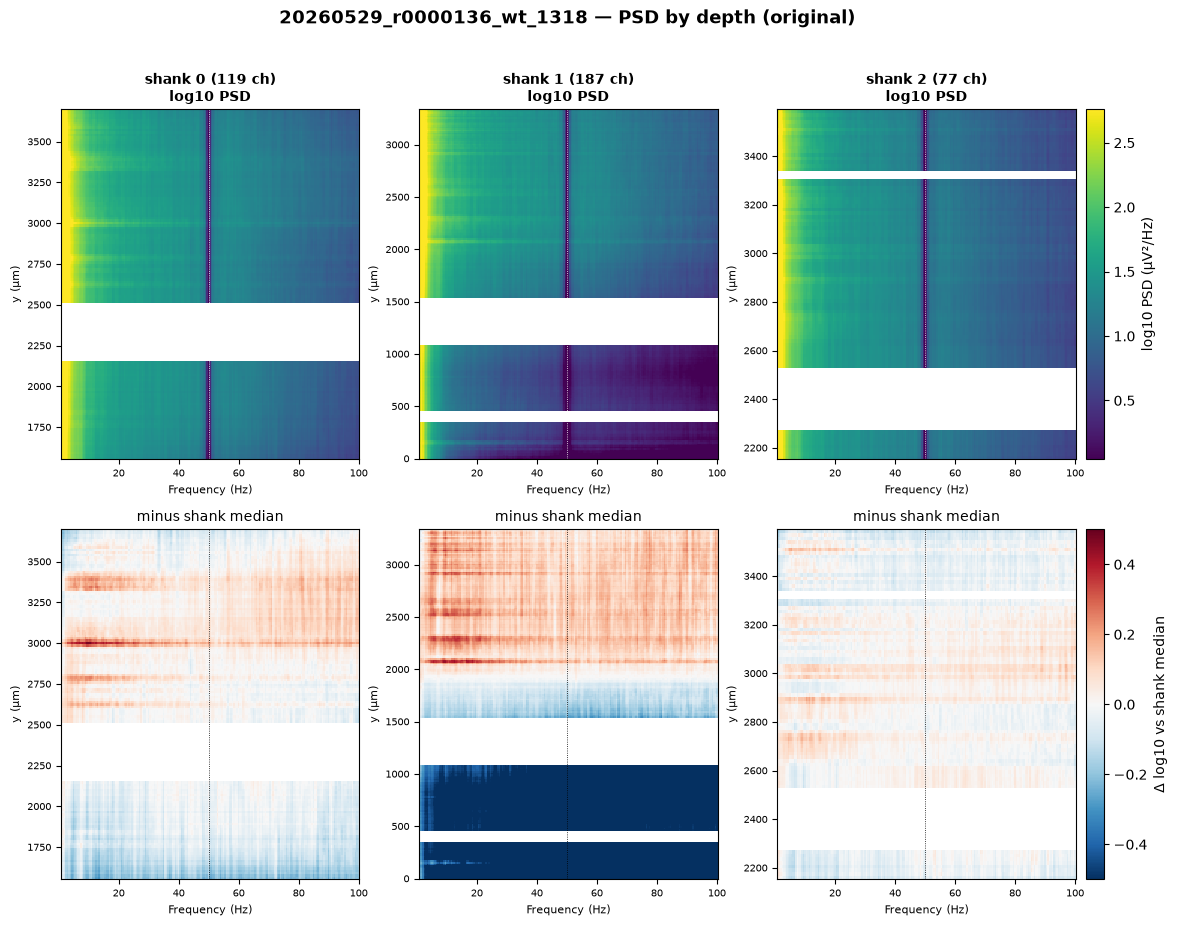

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\signal_QC\psd_depth_CMR.png


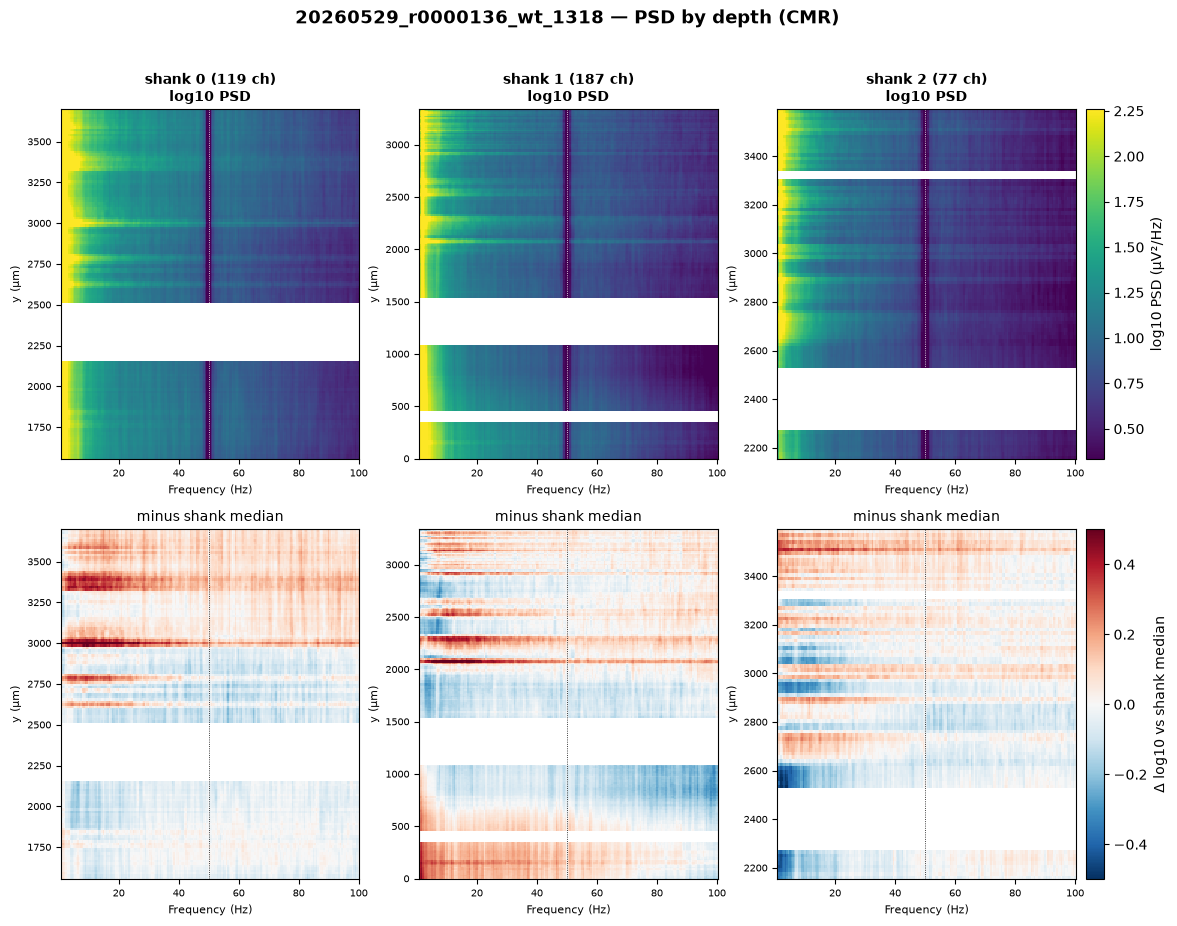

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\signal_QC\psd_original_vs_CMR.png


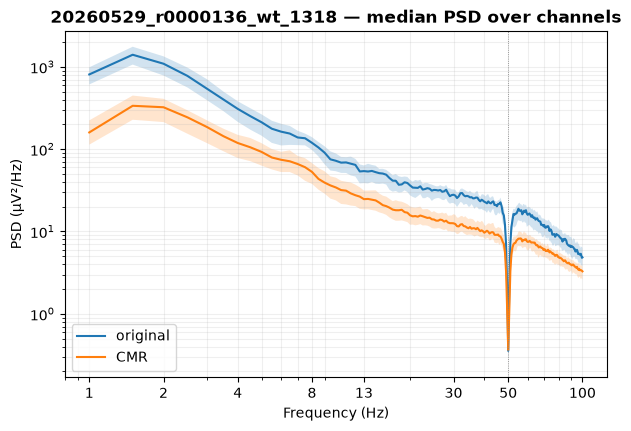

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\signal_QC\traces_original.png


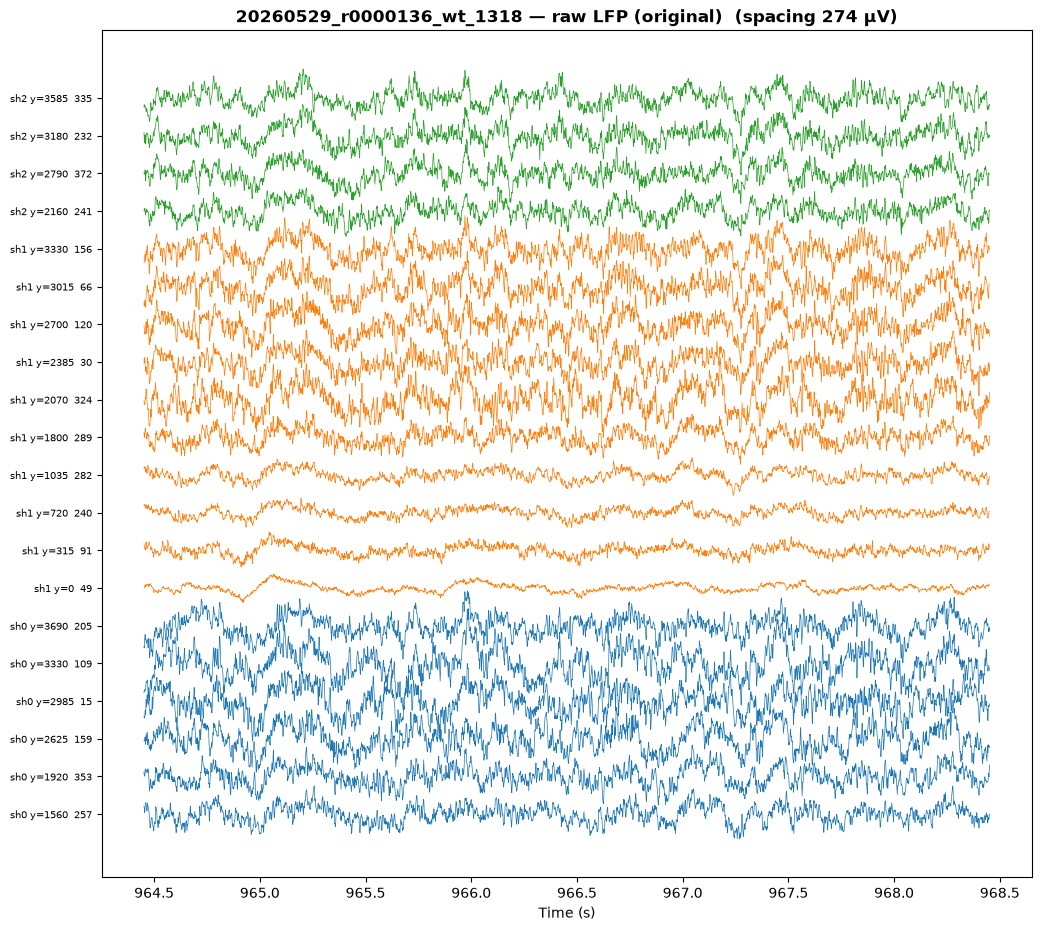

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\signal_QC\traces_CMR.png


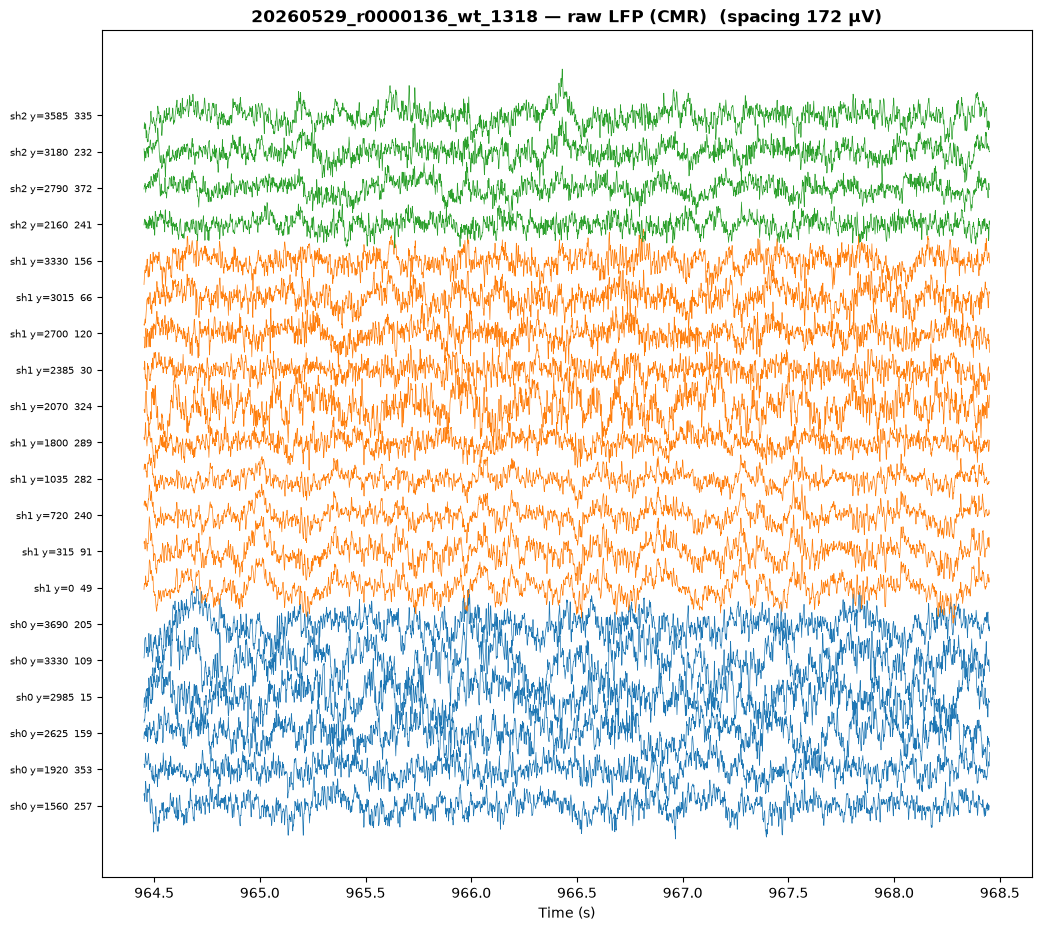

In [5]:
# %%
# ── 3.1 PSD per channel, original and CMR ──
QC_DIR = os.path.join(OUT_DIR, "signal_QC")
os.makedirs(QC_DIR, exist_ok=True)

psd, qc = {}, {}
for ref, rec in recordings.items():
    freqs, psd[ref], qc_ids = lfm.compute_psd(rec, n_segments=30, seg_s=10)
    qc[ref] = lfm.psd_table(freqs, psd[ref], qc_ids, probe_df)
    qc[ref].to_csv(os.path.join(QC_DIR, f"psd_table_{ref}.csv"), index=False)
    print(f"{ref}: PSD done ({len(qc_ids)} channels) | 50 Hz ratio median "
          f"{qc[ref]['line_ratio'].median():.2f}, max {qc[ref]['line_ratio'].max():.2f}")

# %%
# ── 3.2 single bad channels: each channel vs its neighbours (±75 µm, same shank) ──
for ref in qc:
    loc = lfm.flag_channels_local(qc[ref], radius_um=75, thr_log=0.3)
    print(f"\n{ref}: {len(loc)} local outliers")
    if len(loc):
        print(loc[["channel_id", "shank", "y", "local_dev"]].round(2).to_string(index=False))

# %%
# ── 3.3 plots: depth x frequency per reference, original vs CMR, raw traces ──
for ref in psd:
    lfm.plot_psd_depth(freqs, psd[ref], qc_ids, probe_df, f"{SESSION} — PSD by depth ({ref})",
                       save_path=os.path.join(QC_DIR, f"psd_depth_{ref}.png"))
lfm.plot_mean_psd(psd, freqs, f"{SESSION} — median PSD over channels",
                  save_path=os.path.join(QC_DIR, "psd_original_vs_CMR.png"))
t0 = ds_orig.get_total_duration() / 2                                    # 4 s from the middle
for ref, rec in recordings.items():
    lfm.plot_traces(rec, selected_df, t0, 4, f"{SESSION} — raw LFP ({ref})",
                    save_path=os.path.join(QC_DIR, f"traces_{ref}.png"))

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 4. Event check (ERPs)
Kept trials in 0.5 blocks. Average LFP around Press (TTL and MA times), Tone and Release, all channels,
original and CMR. Checks: (1) clear response at 0 s = correct alignment; (2) TTL vs MA press: sharper
average = better alignment; (3) median of all channels (original) = is the shared signal event-locked?

</div>

original Press_TTL : n = 142 trials
original Press_MA  : n = 141 trials
original Tone      : n = 123 trials
original Release   : n = 142 trials
CMR      Press_TTL : n = 142 trials
CMR      Press_MA  : n = 141 trials
CMR      Tone      : n = 123 trials
CMR      Release   : n = 142 trials
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\event_check\erp_depth_Press_TTL_original.png


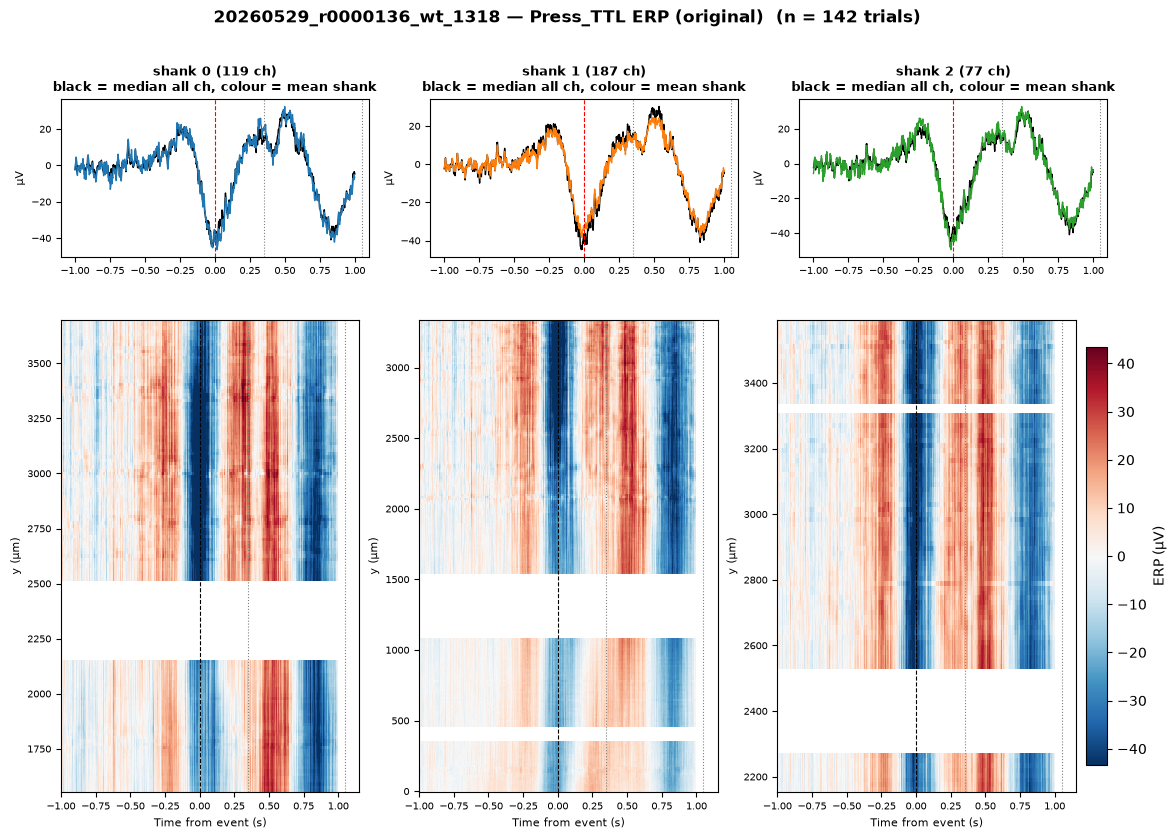

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\event_check\erp_depth_Tone_original.png


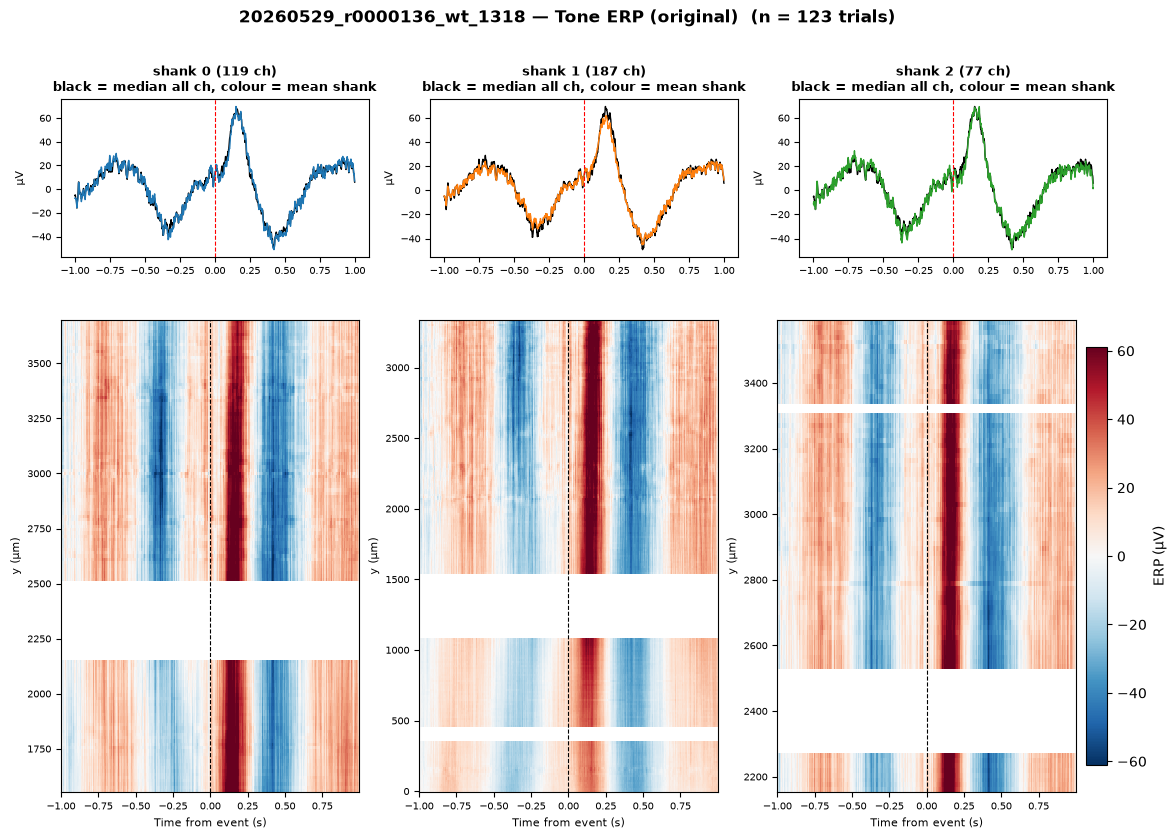

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\event_check\erp_depth_Release_original.png


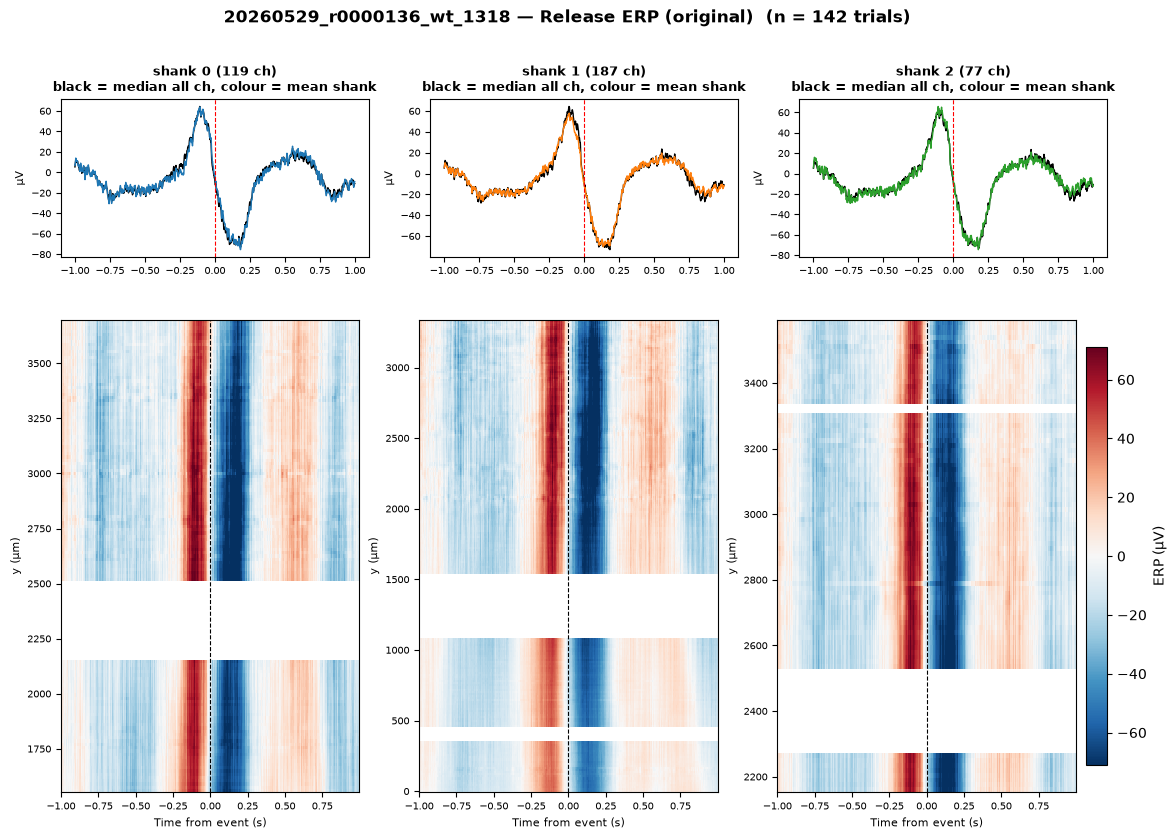

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\event_check\erp_depth_Press_TTL_CMR.png


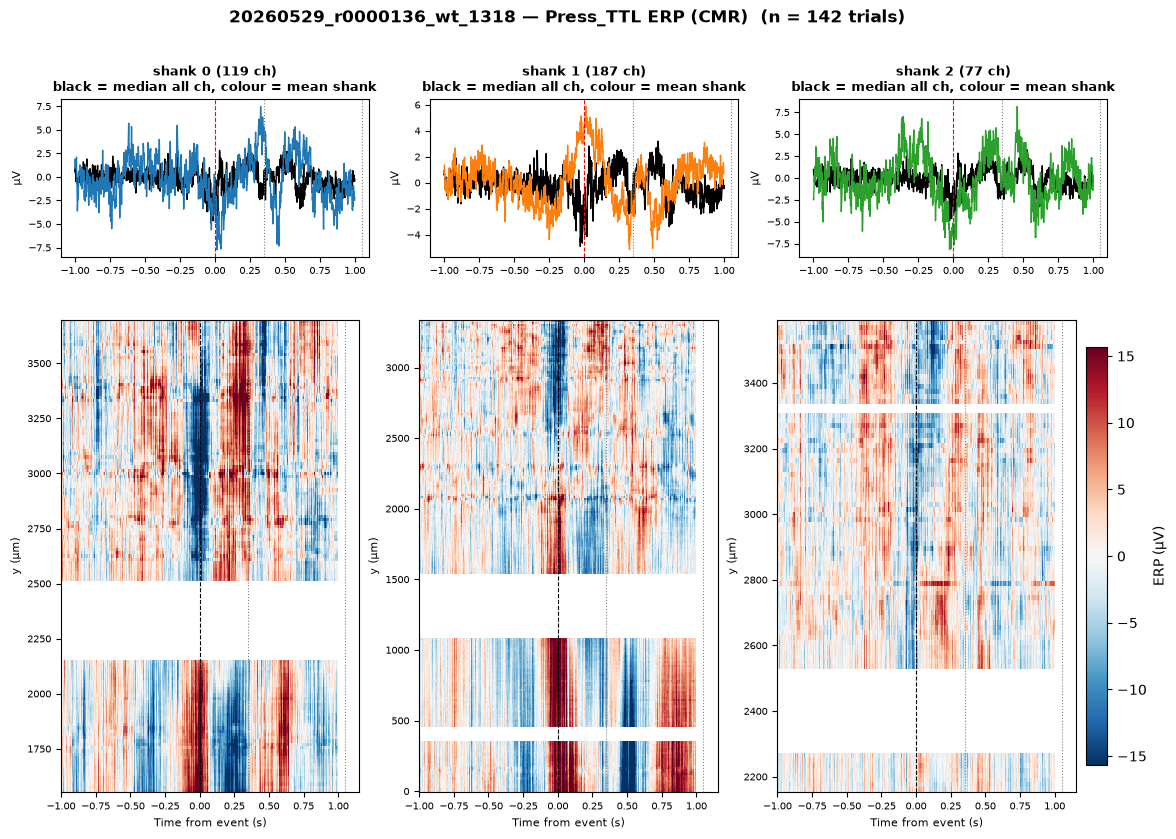

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\event_check\erp_depth_Tone_CMR.png


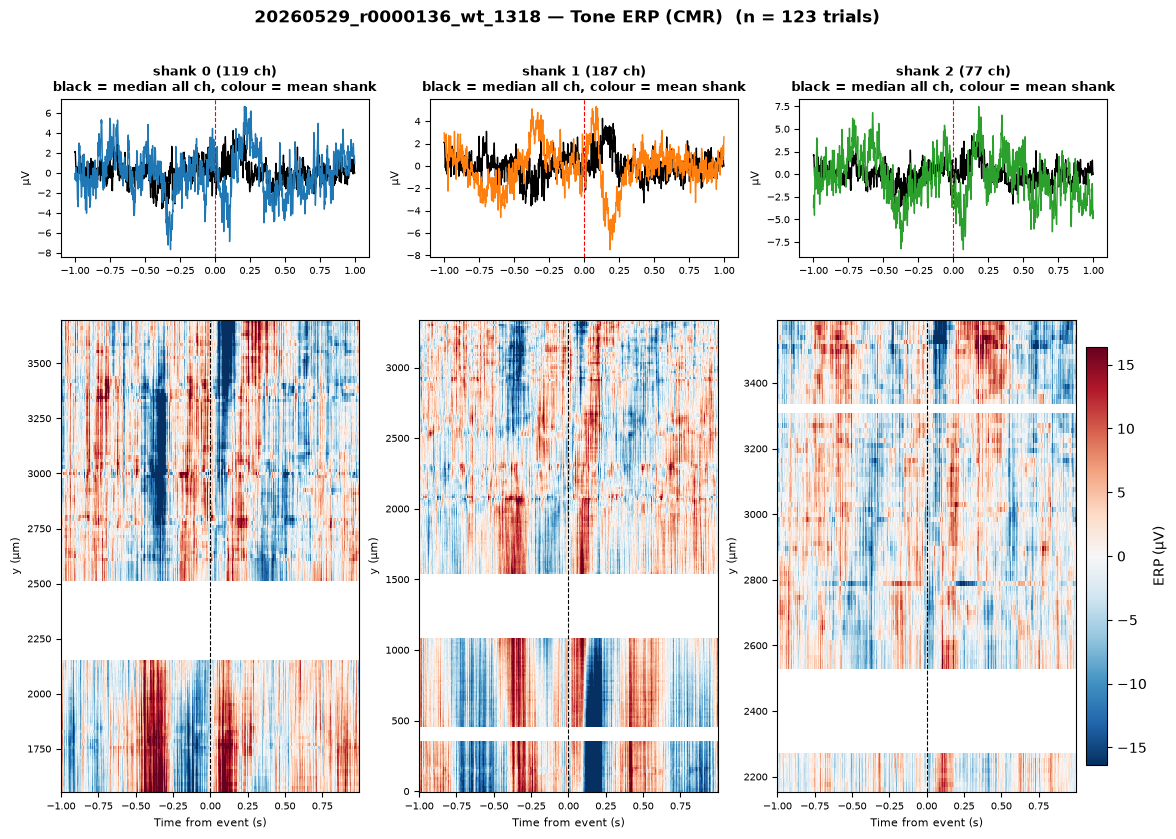

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\event_check\erp_depth_Release_CMR.png


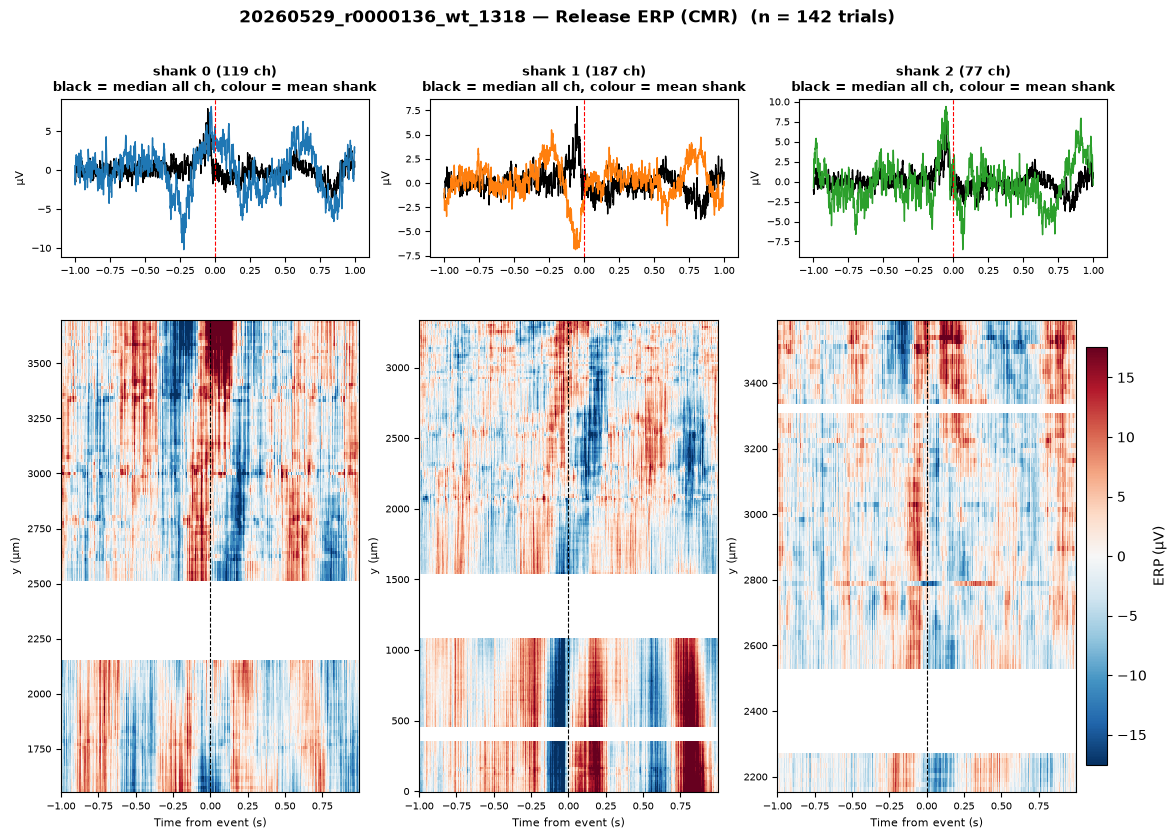

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\event_check\erp_press_TTL_vs_MA_original.png


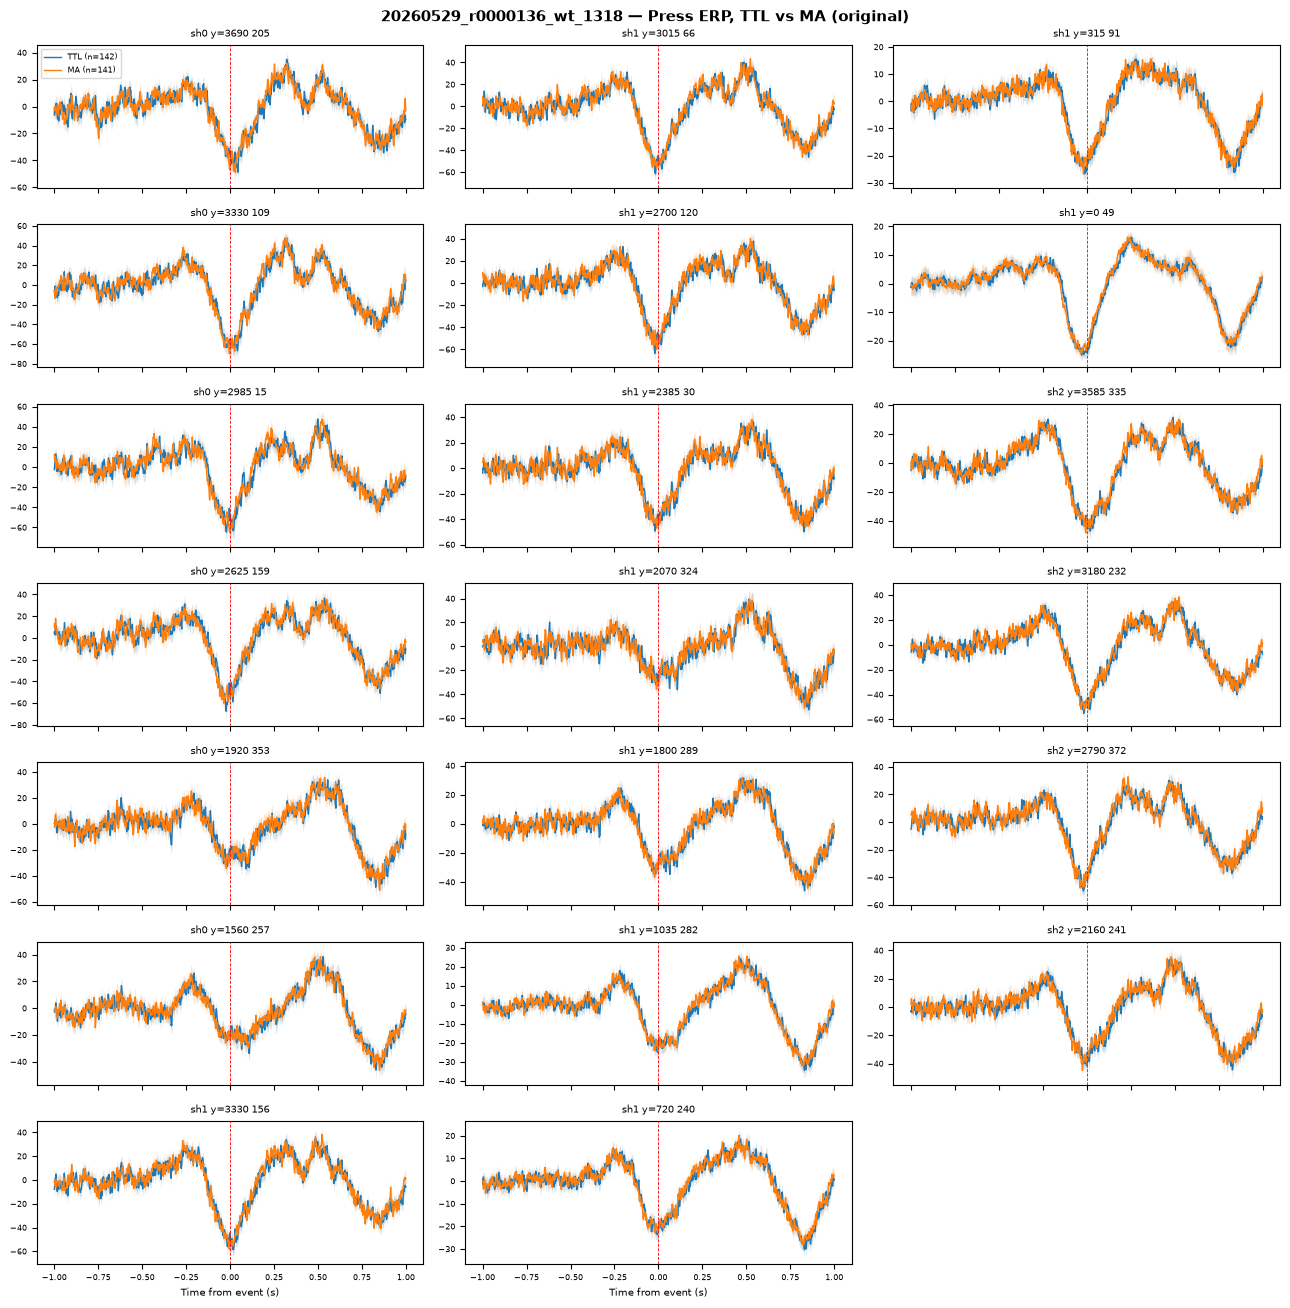

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\event_check\erp_press_TTL_vs_MA_CMR.png


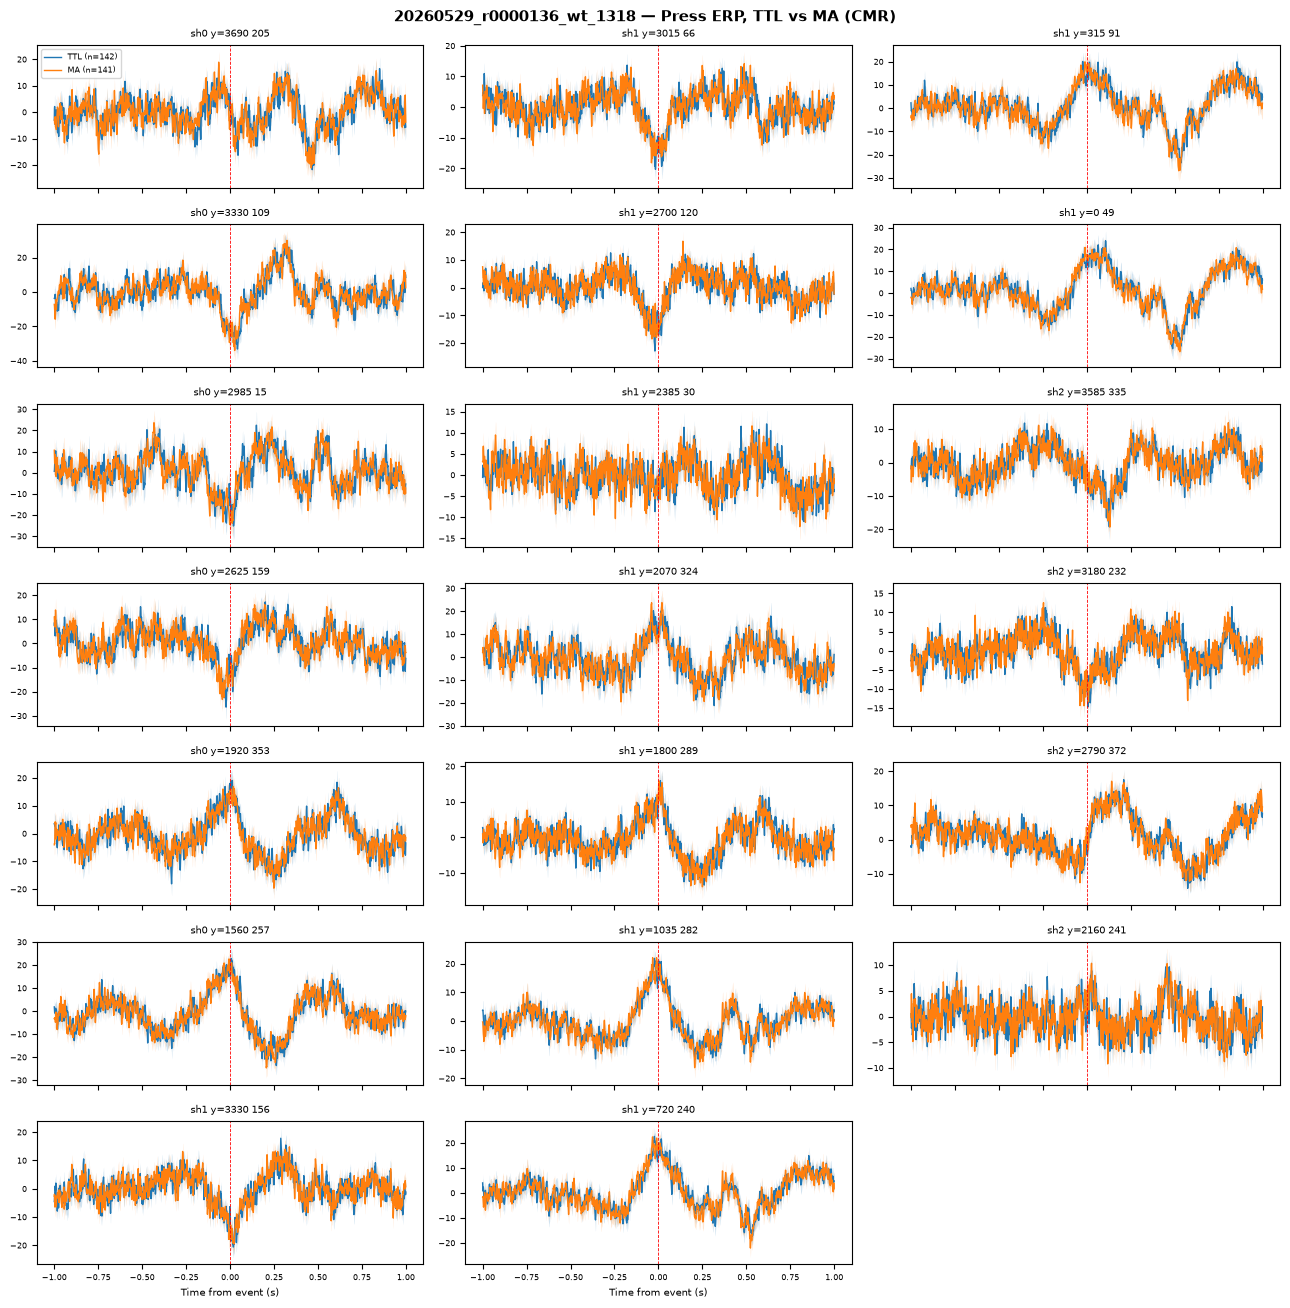

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\event_check\erp_press_original_vs_CMR.png


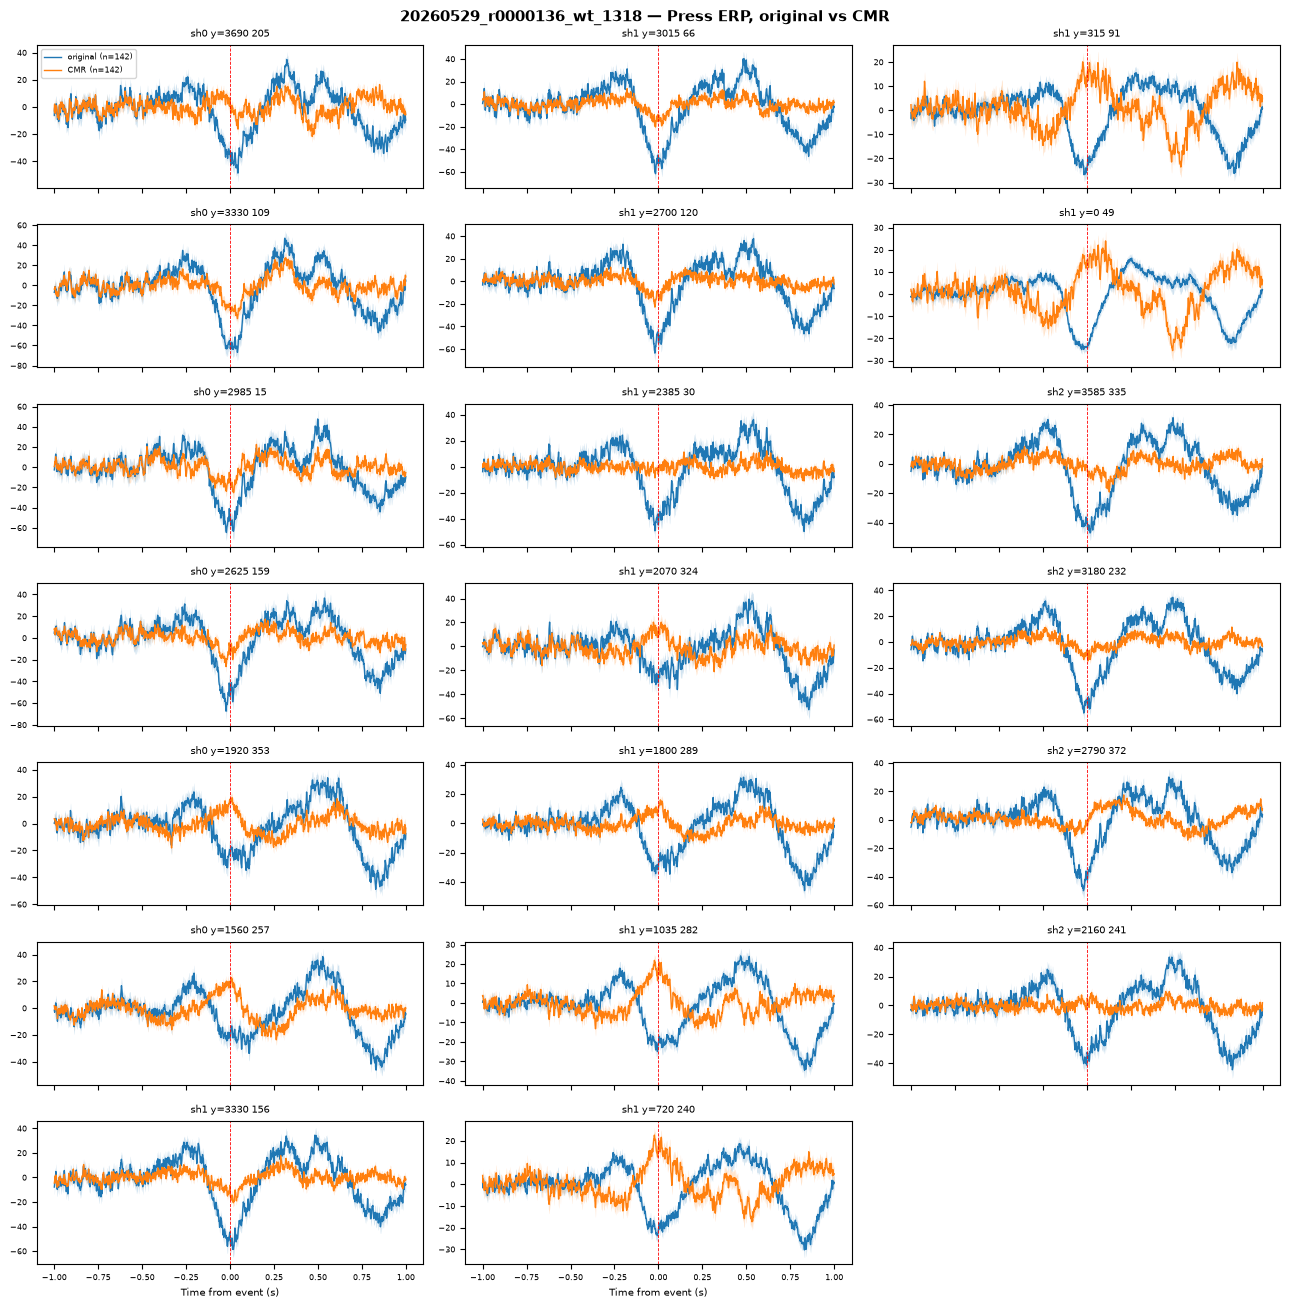

original: ERP size TTL / MA, median over channels = 0.974 | channels with TTL larger: 122 / 383
CMR: ERP size TTL / MA, median over channels = 0.985 | channels with TTL larger: 162 / 383


In [6]:
# %%
# ── 4.1 event times + ERPs (original and CMR) ──
EV_DIR = os.path.join(OUT_DIR, "event_check")
ev_times = {
    "Press_TTL": beh["press_np_s"].values,                    # TTL-anchored (section 1)
    "Press_MA":  T.loc[beh.index, "press_np_s"].values,       # MA-mapped press, only for the comparison
    "Tone":      beh["tone_np_s"].values,                     # NaN for early trials (no tone) -> skipped
    "Release":   beh["release_np_s"].values,
}
erps = {}
for ref, rec in recordings.items():
    for name, times_s in ev_times.items():
        erps[(ref, name)] = lfm.event_erp(rec, times_s, tmin=-1.0, tmax=1.0)
        print(f"{ref:8s} {name:10s}: n = {erps[(ref, name)]['n']} trials")

# %%
# ── 4.2 depth maps per event and reference ──
marks = {"Press_TTL": {"tone short": 0.35, "tone long": 1.05}}
for (ref, name), e in erps.items():
    if name == "Press_MA":
        continue
    lfm.plot_erp_depth(e, probe_df, f"{SESSION} — {name} ERP ({ref})", marks=marks.get(name),
                       save_path=os.path.join(EV_DIR, f"erp_depth_{name}_{ref}.png"))

# %%
# ── 4.3 selected channels: TTL vs MA press, and original vs CMR ──
for ref in recordings:
    lfm.plot_erp_traces({"TTL": erps[(ref, "Press_TTL")], "MA": erps[(ref, "Press_MA")]}, selected_df,
                        f"{SESSION} — Press ERP, TTL vs MA ({ref})",
                        save_path=os.path.join(EV_DIR, f"erp_press_TTL_vs_MA_{ref}.png"))
lfm.plot_erp_traces({"original": erps[("original", "Press_TTL")], "CMR": erps[("CMR", "Press_TTL")]},
                    selected_df, f"{SESSION} — Press ERP, original vs CMR",
                    save_path=os.path.join(EV_DIR, "erp_press_original_vs_CMR.png"))

# %%
# ── 4.4 TTL vs MA: which alignment gives the sharper average? ──
for ref in recordings:
    sh = lfm.alignment_sharpness(erps[(ref, "Press_TTL")], erps[(ref, "Press_MA")], window=(-0.1, 0.3))
    print(f"{ref}: ERP size TTL / MA, median over channels = {sh['ratio_a_b'].median():.3f} | "
          f"channels with TTL larger: {(sh['ratio_a_b'] > 1).sum()} / {len(sh)}")

In [7]:
# %%
# ── 4.5 channels that stand out in the ERP (vs neighbours ±75 µm), CMR ──
for name in ["Press_TTL", "Tone", "Release"]:
    e = erps[("CMR", name)]
    t = pd.DataFrame({"channel_id": e["channel_ids"], "log_erp_sd": np.log10(e["mean"].std(axis=0))})
    t = t.merge(probe_df[["channel_id", "shank", "y"]], on="channel_id")
    out = lfm.flag_channels_local(t, col="log_erp_sd", radius_um=75, thr_log=0.3)
    print(f"\n{name}: {len(out)} channels with ERP size > 2x or < 0.5x their neighbours")
    if len(out):
        print(out[["channel_id", "shank", "y", "local_dev"]].round(2).to_string(index=False))

# ── 3 early trials with a tone time ──
x = beh[beh["tone_np_s"].notna()]
print("\ntrials with a tone time:"); print(x.groupby(["outcome", "type"]).size().to_string())
odd = x[x["outcome"] == "early"].index
print(T.loc[odd, ["type", "hold_s", "tone_delay_s", "rt_s", "timing_mismatch"]].round(3))


Press_TTL: 0 channels with ERP size > 2x or < 0.5x their neighbours

Tone: 0 channels with ERP size > 2x or < 0.5x their neighbours

Release: 0 channels with ERP size > 2x or < 0.5x their neighbours

trials with a tone time:
outcome  type 
correct  long     49
         short    48
early    long      1
late     long      3
         short    22
       type  hold_s  tone_delay_s  rt_s  timing_mismatch
trial                                                   
51     long    1.02          1.05 -0.03             True


 <div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 5a. TFR per condition (21 selected channels) — descriptive, no statistics
Morlet TFR (band-specific cycles), −3 to +5 s around Press / Tone / Release (TTL-anchored times).
% change from ONE common pre-press baseline (−0.5 to −0.2 s, all kept trials in 0.5 blocks, per channel).
Conditions: correct / early (hold > 0.3 s for long) / late × long / short. Early: no Tone column.
CMR (main) and original; FULL (1–99 Hz) and ZOOM (1–15 Hz); colour scale ±100 %.

 </div>

In [8]:
# %%
# ── 5a.1 compute (21 channels x 6 conditions x 3 events x 2 references) ──
import io, contextlib, pickle
TFR_DIR = os.path.join(OUT_DIR, "TFR_conditions_20ch")
REFS_5A = ["CMR", "original"]
cond_src = {"correct long": groups[("correct", "long")], "correct short": groups[("correct", "short")],
            "early long (hold>0.3)": groups[("early", "long-filtered")], "early short": groups[("early", "short")],
            "late long": groups[("late", "long")], "late short": groups[("late", "short")]}
COND_5A = {f"{k} (n={len(v)})": v for k, v in cond_src.items()}

tfr5, times5, freqs5 = {}, {}, None
for ref in REFS_5A:
    rec = recordings[ref]
    tfr5[ref] = {ev: {} for ev in ALIGNMENTS}
    for i, ch in enumerate(selected_df["channel_id"]):
        with contextlib.redirect_stdout(io.StringIO()):                     # silence per-event prints
            ref_pow = tfx.extract_raw_power(rec, all_trials, ch, {"Press": EVENTS["Press"]},
                                            BAND_SETTINGS, TMIN, TMAX, fs)
            base = tfx.get_baseline_values(ref_pow["Press"], BASELINE_WINDOW)  # common pre-press baseline
            for ev in ALIGNMENTS:
                tfr5[ref][ev][ch] = {}
            for cname, trials in COND_5A.items():
                evs = {k: v for k, v in EVENTS.items() if not (k == "Tone" and cname.startswith("early"))}
                raw = tfx.extract_raw_power(rec, trials, ch, evs, BAND_SETTINGS, TMIN, TMAX, fs)
                for ev in evs:
                    res, times5[ev], freqs5 = tfx.compute_common_baseline(
                        {ev: raw[ev]}, BAND_SETTINGS, base, ALIGNMENTS[ev]["crop"], mode="pct")
                    tfr5[ref][ev][ch][cname] = res[ev]
        print(f"{ref}: {i + 1}/{len(selected_df)} channels done")

os.makedirs(TFR_DIR, exist_ok=True)
with open(os.path.join(TFR_DIR, "tfr5_results.pkl"), "wb") as f:
    pickle.dump({"tfr5": tfr5, "times5": times5, "freqs5": freqs5, "conditions": list(COND_5A)}, f)
print("saved:", os.path.join(TFR_DIR, "tfr5_results.pkl"))



CMR: 1/20 channels done
CMR: 2/20 channels done
CMR: 3/20 channels done
CMR: 4/20 channels done
CMR: 5/20 channels done
CMR: 6/20 channels done
CMR: 7/20 channels done
CMR: 8/20 channels done
CMR: 9/20 channels done
CMR: 10/20 channels done
CMR: 11/20 channels done
CMR: 12/20 channels done
CMR: 13/20 channels done
CMR: 14/20 channels done
CMR: 15/20 channels done
CMR: 16/20 channels done
CMR: 17/20 channels done
CMR: 18/20 channels done
CMR: 19/20 channels done
CMR: 20/20 channels done
original: 1/20 channels done
original: 2/20 channels done
original: 3/20 channels done
original: 4/20 channels done
original: 5/20 channels done
original: 6/20 channels done
original: 7/20 channels done
original: 8/20 channels done
original: 9/20 channels done
original: 10/20 channels done
original: 11/20 channels done
original: 12/20 channels done
original: 13/20 channels done
original: 14/20 channels done
original: 15/20 channels done
original: 16/20 channels done
original: 17/20 channels done
original

In [9]:
# %%
# ── 5a.2 plots: per reference x event x FULL/ZOOM, 7 channels per figure ──
#    colour scale: CMR ±100 % (main), original ±500 % (its shared 4–12 Hz increase is much larger)
VMAX_5A = {"CMR": 100, "original": 100}
FREQ_VIEWS = {"FULL": (FULL_FREQ_RANGE, FULL_YTICKS), "ZOOM": (ZOOM_FREQ_RANGE, ZOOM_YTICKS)}
ROWS_PER_FIG = 7
order = selected_df.sort_values(["shank", "y"]).reset_index(drop=True)      # per shank, deepest first
contour = ds_orig.get_probe().probe_planar_contour

def tone_line(cname):                                                       # red tone line in Press plots
    if cname.startswith("early"):
        return None
    return TONE_DELAY["short"] if "short" in cname else TONE_DELAY["long"]

for ref in tfr5:
    for ev in ALIGNMENTS:
        names = [c for c in COND_5A if not (ev == "Tone" and c.startswith("early"))]
        vlines = {c: tone_line(c) for c in names} if ev == "Press" else None
        for view, (frange, yticks) in FREQ_VIEWS.items():
            for k in range(0, len(order), ROWS_PER_FIG):
                part = order.iloc[k:k + ROWS_PER_FIG]
                tfx.plot_across_channels(
                    tfr5[ref][ev], times5[ev], freqs5, names, part, probe_df, "Press",
                    f"{SESSION} — {ev}-aligned, {ref} — % change from common pre-press baseline "
                    f"(scale ±{VMAX_5A[ref]} %)",
                    freq_range=frange, yticks=yticks, band_boundaries=OSCILLATION_BOUNDARIES,
                    save_path=os.path.join(TFR_DIR, ref, ev, view, f"channels_{k + 1}-{k + len(part)}.png"),
                    vmax=VMAX_5A[ref], contour=contour, vlines=vlines, mode="pct", show=False)
print("all figures saved in", TFR_DIR)

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\TFR_conditions_20ch\CMR\Press\FULL\channels_1-7.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\TFR_conditions_20ch\CMR\Press\FULL\channels_8-14.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\TFR_conditions_20ch\CMR\Press\FULL\channels_15-20.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\TFR_conditions_20ch\CMR\Press\ZOOM\channels_1-7.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\TFR_conditions_20ch\CMR\Press\ZOOM\channels_8-14.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\pilot\TFR_conditions_20ch\CMR\Press\ZOOM

In [10]:
# %%
# ── 5a.3 numeric summary of the TFR results (% change from the common pre-press baseline) ──
import pickle
with open(os.path.join(TFR_DIR, "tfr5_results.pkl"), "rb") as f:
    _r = pickle.load(f)
tfr5, times5, freqs5 = _r["tfr5"], _r["times5"], _r["freqs5"]

bands = {"delta 1-3": (1, 3), "theta 4-7": (4, 7), "alpha 8-12": (8, 12), "beta 13-29": (13, 29),
         "lowG 30-60": (30, 60), "highG 61-100": (61, 100)}
rows = []
for ref in tfr5:
    for ev in tfr5[ref]:
        t = times5[ev]
        for cname in next(iter(tfr5[ref][ev].values())):
            M = np.stack([tfr5[ref][ev][ch][cname] for ch in tfr5[ref][ev]])     # (channels, freqs, times)
            row = {"ref": ref, "event": ev, "condition": cname.split(" (")[0],
                   "median_%": round(float(np.nanmedian(M)), 1),
                   "p05_%": round(float(np.nanpercentile(M, 5)), 1),
                   "p95_%": round(float(np.nanpercentile(M, 95)), 1),
                   "share>100%": round(float(np.mean(M > 100)), 3)}
            for b, (lo, hi) in bands.items():
                row[b] = round(float(np.nanmedian(M[:, (freqs5 >= lo) & (freqs5 <= hi)])), 1)
            if ev == "Press":                                                    # baseline window itself
                bw = (t >= BASELINE_WINDOW[0]) & (t <= BASELINE_WINDOW[1])
                row["in_baseline_%"] = round(float(np.nanmedian(M[:, :, bw])), 1)
            rows.append(row)
s5 = pd.DataFrame(rows)
s5.to_csv(os.path.join(TFR_DIR, "tfr5_summary.csv"), index=False)
pd.set_option("display.width", 250)
print(s5.to_string(index=False))

     ref   event     condition  median_%  p05_%  p95_%  share>100%  delta 1-3  theta 4-7  alpha 8-12  beta 13-29  lowG 30-60  highG 61-100  in_baseline_%
     CMR   Press  correct long      -2.7  -27.4   26.9       0.000       -4.0       -1.6        -0.1        -2.2        -0.5          -5.0           -0.4
     CMR   Press correct short      -4.4  -30.4   28.3       0.000       -0.2       -5.6        -2.4        -1.2        -1.7          -8.3            0.1
     CMR   Press    early long      -5.1  -40.8   44.1       0.001       -2.1       -2.9        -5.2        -3.2        -2.8          -8.3           -3.3
     CMR   Press   early short     -20.5  -83.5  131.2       0.083      -16.6       -7.2       -20.0       -16.8       -15.1         -27.4          -10.8
     CMR   Press     late long     -12.5  -73.5  109.9       0.062      -18.6       -7.0       -15.1       -15.4       -11.6         -11.5          -14.4
     CMR   Press    late short      -4.1  -35.4   37.0       0.000        1.


 <div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">
 
## 5b. Which band is different DURING THE HOLD (not before the press, not after the release)?
Per trial and channel, mean power per band in 3 windows of the SAME trial:
 - **PRE**  : Press −0.5 → −0.2 s (before the press)
 - **HOLD** : Press-aligned hold window (correct long 0.20 → 0.85 s: away from the press movement and the tone at 1.05 s)
 - **POST** : Release +0.2 → +0.5 s (after the release)
 Per trial: log10(HOLD / PRE) and log10(HOLD / POST). Test: sign-flip across trials (mean log ratio = 0?),
 5000 flips, raw p. **Hold-specific** = HOLD differs from PRE **and** from POST, in the same direction.

  </div>

In [2]:
# %%
# ── 5b.1 compute + test (both references, 20 channels) ──
import io, contextlib
B5_BANDS = {"delta 1-3": (1, 3), "theta 4-7": (4, 7), "theta 7.5-9.5": (7.5, 9.5), "alpha 8-12": (8, 12),
            "theta+alpha 4-12": (4, 12), "beta 13-29": (13, 29), "lowG 30-60": (30, 60), "highG 61-100": (61, 100)}
B5_PRE, B5_POST = (-0.5, -0.2), (0.2, 0.5)
B5_CONDS = {"correct long":               {"trials": groups[("correct", "long")],         "hold": (0.20, 0.85)},
            "correct long (0.10-0.30)":   {"trials": groups[("correct", "long")],         "hold": (0.10, 0.30)},
            "early long (hold>0.3)":      {"trials": groups[("early", "long-filtered")], "hold": (0.10, 0.30)}}
B5_GAP = 0.1                     # hold window must end >= 0.1 s before that trial's release
B5_DIR = os.path.join(OUT_DIR, "5b_hold_vs_pre_post")
os.makedirs(B5_DIR, exist_ok=True)

def _win_mean(power, times, win):                          # (trials, freqs, times) -> (trials, freqs)
    m = (times >= win[0] - 1e-9) & (times <= win[1] + 1e-9)
    return power[:, :, m].mean(axis=2)

b5_rows = []
for ref in ["CMR", "original"]:
    rec = recordings[ref]
    for cname, c in B5_CONDS.items():
        tr = c["trials"]
        tr = tr[(tr["release"] - tr["press"]) >= c["hold"][1] + B5_GAP]        # whole hold window inside the hold
        print(f"[{ref}] {cname}: n = {len(tr)} trials | hold window {c['hold']}")
        for ch in selected_df["channel_id"]:
            with contextlib.redirect_stdout(io.StringIO()):
                pP, tP, freqs, kP = tfs.extract_single_trial_power(
                    rec, tr, ch, EVENTS["Press"], CONFIG["band_settings"], CONFIG["tmin"], CONFIG["tmax"], fs,
                    keep_window=(B5_PRE[0] - 0.05, c["hold"][1] + 0.05), decim=DECIM)
                pR, tR, _, kR = tfs.extract_single_trial_power(
                    rec, tr, ch, EVENTS["Release"], CONFIG["band_settings"], CONFIG["tmin"], CONFIG["tmax"], fs,
                    keep_window=(B5_POST[0] - 0.05, B5_POST[1] + 0.05), decim=DECIM)
            both = [t for t in kP if t in set(kR)]                              # same trials in all 3 windows
            iP, iR = [kP.index(t) for t in both], [kR.index(t) for t in both]
            pre  = _win_mean(pP[iP], tP, B5_PRE)
            hold = _win_mean(pP[iP], tP, c["hold"])
            post = _win_mean(pR[iR], tR, B5_POST)
            for b, (lo, hi) in B5_BANDS.items():
                fm = (freqs >= lo) & (freqs <= hi)
                H, P0, P1 = hold[:, fm].mean(1), pre[:, fm].mean(1), post[:, fm].mean(1)
                r_pre, r_post = np.log10(H / P0), np.log10(H / P1)               # one value per trial
                s_pre  = tfs.sign_flip_test(r_pre,  n_perm=N_PERMUTATIONS, seed=SEED)
                s_post = tfs.sign_flip_test(r_post, n_perm=N_PERMUTATIONS, seed=SEED)
                b5_rows.append({"ref": ref, "condition": cname, "channel": ch, "band": b, "n": len(both),
                                "hold_vs_pre_%":  round(100 * (10 ** r_pre.mean() - 1), 1),  "p_pre":  round(s_pre["p"], 4),
                                "hold_vs_post_%": round(100 * (10 ** r_post.mean() - 1), 1), "p_post": round(s_post["p"], 4)})
        print(f"[{ref}] {cname}: done")

b5 = pd.DataFrame(b5_rows)
ys, shk = probe_df.set_index("channel_id")["y"], probe_df.set_index("channel_id")["shank"]
b5.insert(3, "shank", b5["channel"].map(shk)); b5.insert(4, "y (um)", b5["channel"].map(ys))
sig_pre, sig_post = b5["p_pre"] < 0.05, b5["p_post"] < 0.05
same_up   = (b5["hold_vs_pre_%"] > 0) & (b5["hold_vs_post_%"] > 0)
same_down = (b5["hold_vs_pre_%"] < 0) & (b5["hold_vs_post_%"] < 0)
b5["result"] = np.select(
    [sig_pre & sig_post & same_up, sig_pre & sig_post & same_down, sig_pre & ~sig_post, ~sig_pre & sig_post],
    ["HOLD UP (vs pre and post)", "HOLD DOWN (vs pre and post)", "differs from pre only", "differs from post only"],
    default="n.s.")
b5.to_csv(os.path.join(B5_DIR, "5b_hold_vs_pre_post.csv"), index=False)
print("saved:", os.path.join(B5_DIR, "5b_hold_vs_pre_post.csv"))

# %%
# ── 5b.2 summary per band: how many of the 20 channels are hold-specific, and the median % ──
pd.set_option("display.width", 250)
for (ref, cname), d in b5.groupby(["ref", "condition"], sort=False):
    t = d.groupby("band", sort=False).agg(
        n_trials=("n", "first"),
        median_hold_vs_pre=("hold_vs_pre_%", "median"), median_hold_vs_post=("hold_vs_post_%", "median"),
        HOLD_UP=("result", lambda s: (s == "HOLD UP (vs pre and post)").sum()),
        HOLD_DOWN=("result", lambda s: (s == "HOLD DOWN (vs pre and post)").sum()),
        pre_only=("result", lambda s: (s == "differs from pre only").sum()),
        post_only=("result", lambda s: (s == "differs from post only").sum()))
    print(f"\n===== {ref} | {cname} (of {d['channel'].nunique()} channels) =====")
    print(t.to_string())

# %%
# ── 5b.3 figure: channels (per shank, deepest first) x bands; colour = % change, * = hold-specific ──
order5 = selected_df.sort_values(["shank", "y"])["channel_id"].tolist()
bands5 = list(B5_BANDS)
for (ref, cname), d in b5.groupby(["ref", "condition"], sort=False):
    fig, axes = plt.subplots(1, 2, figsize=(13, 8), sharey=True)
    for ax, col, pcol, ttl in zip(axes, ["hold_vs_pre_%", "hold_vs_post_%"], ["p_pre", "p_post"],
                                  ["HOLD vs PRE (% change)", "HOLD vs POST (% change)"]):
        M = d.pivot(index="channel", columns="band", values=col).loc[order5, bands5]
        im = ax.imshow(M.values, cmap="RdBu_r", vmin=-50, vmax=50, aspect="auto")
        R = d.pivot(index="channel", columns="band", values="result").loc[order5, bands5]
        P = d.pivot(index="channel", columns="band", values=pcol).loc[order5, bands5]
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                if R.iat[i, j].startswith("HOLD"):
                    ax.text(j, i, "*", ha="center", va="center", fontsize=14, fontweight="bold")
                elif P.iat[i, j] < 0.05:
                    ax.text(j, i, "·", ha="center", va="center", fontsize=14)
        ax.set_xticks(range(len(bands5))); ax.set_xticklabels(bands5, rotation=45, ha="right")
        ax.set_title(ttl)
    axes[0].set_yticks(range(len(order5)))
    axes[0].set_yticklabels([f"sh{shk[c]} y={ys[c]:.0f} {c.split('#')[1]}" for c in order5], fontsize=8)
    fig.colorbar(im, ax=axes, label="% change (geometric mean over trials)")
    fig.suptitle(f"{SESSION} — 5b {cname}, {ref} | * = hold-specific (p<0.05 vs pre AND vs post, same sign), "
                 f"· = p<0.05 in this panel only", fontsize=10)
    fig.savefig(os.path.join(B5_DIR, f"5b_{ref}_{cname.split(' (')[0].replace(' ', '_')}.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

NameError: name 'groups' is not defined

In [7]:
B5_DIR = os.path.join(OUT_DIR, "5b_hold_vs_pre_post")
b5 = pd.read_csv(os.path.join(B5_DIR, "5b_hold_vs_pre_post.csv"))
print(b5.groupby(["ref", "condition"])["n"].first())

ref       condition               
CMR       correct long                49
          correct long (0.10-0.30)    49
          early long (hold>0.3)       14
original  correct long                49
          correct long (0.10-0.30)    49
          early long (hold>0.3)       14
Name: n, dtype: int64


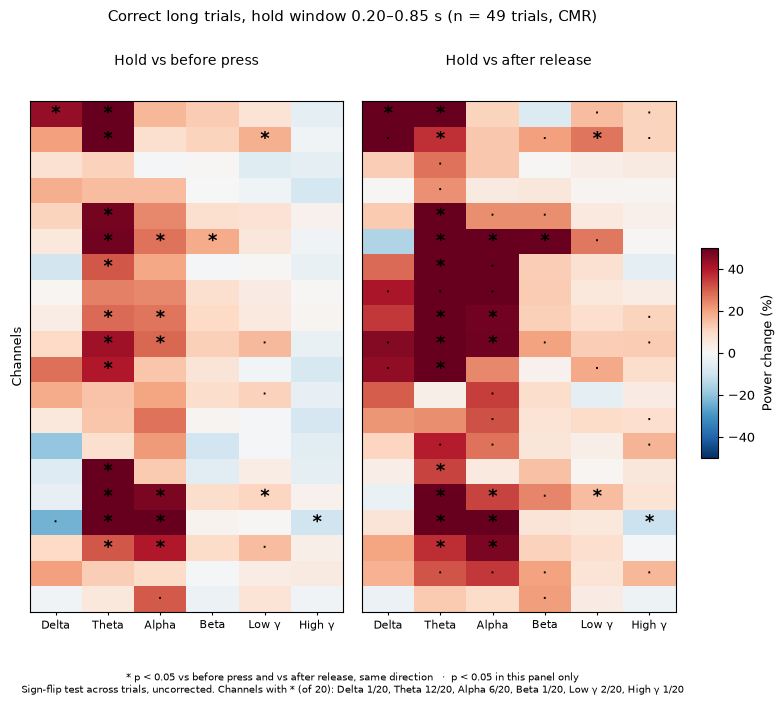

saved in C:\Users\ar687\Desktop


In [13]:
# ── Pilot slide figure: correct long, CMR, hold 0.20-0.85 s, six bands (needs b5 loaded) ──
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
REF, COND = "CMR", "correct long"
BANDS  = ["delta 1-3", "theta 4-7", "alpha 8-12", "beta 13-29", "lowG 30-60", "highG 61-100"]
NAMES  = ["Delta", "Theta", "Alpha", "Beta", "Low γ", "High γ"]
RANGES = ["1–3 Hz", "4–7 Hz", "8–12 Hz", "13–29 Hz", "30–60 Hz", "61–100 Hz"]

d = b5[(b5["ref"] == REF) & (b5["condition"] == COND) & (b5["band"].isin(BANDS))]
order = selected_df.sort_values(["shank", "y"])["channel_id"].tolist()
ys, shk = probe_df.set_index("channel_id")["y"], probe_df.set_index("channel_id")["shank"]
n_tr = int(d["n"].iloc[0])

R = d.pivot(index="channel", columns="band", values="result").loc[order, BANDS]
k_spec = R.apply(lambda c: c.str.startswith("HOLD")).sum()                       # channels with * per band
counts = ", ".join(f"{n} {k_spec[b]}/{len(order)}" for n, b in zip(NAMES, BANDS))

plt.rcParams.update({"font.size": 9, "axes.linewidth": 0.8})
fig, axes = plt.subplots(1, 2, figsize=(8.5, 7), sharey=True)
for ax, col, pcol, ttl in zip(axes, ["hold_vs_pre_%", "hold_vs_post_%"], ["p_pre", "p_post"],
                              ["Hold vs before press", "Hold vs after release"]):
    M = d.pivot(index="channel", columns="band", values=col).loc[order, BANDS]
    P = d.pivot(index="channel", columns="band", values=pcol).loc[order, BANDS]
    im = ax.imshow(M.values, cmap="RdBu_r", vmin=-50, vmax=50, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if R.iat[i, j].startswith("HOLD"):
                ax.text(j, i, "*", ha="center", va="center", fontsize=13, fontweight="bold")
            elif P.iat[i, j] < 0.05:
                ax.text(j, i, "·", ha="center", va="center", fontsize=13)
    ax.set_xticks(range(len(BANDS))); ax.set_xticklabels(NAMES, fontsize=8)      # bottom: band name only
    ax.set_title(ttl, fontsize=10, pad=26)
    ax.tick_params(length=2)
    for a in (ax, ax2):                                                          # frame
        for s in a.spines.values():
            s.set_visible(True); s.set_linewidth(0.8); s.set_color("k")
axes[0].set_yticks([])
axes[0].set_ylabel("Channels")
fig.suptitle(f"Correct long trials, hold window 0.20–0.85 s (n = {n_tr} trials, CMR)", fontsize=10.5, y=0.99)
fig.text(0.5, 0.01, "* p < 0.05 vs before press and vs after release, same direction   ·  p < 0.05 in this panel only\n"
         "Sign-flip test across trials, uncorrected. Channels with * (of 20): " + counts,
         ha="center", va="bottom", fontsize=7)
fig.subplots_adjust(bottom=0.13, top=0.86, left=0.12, right=0.88, wspace=0.06)
cax = fig.add_axes([0.91, 0.35, 0.02, 0.3])
cb = fig.colorbar(im, cax=cax); cb.set_label("Power change (%)")

desk = os.path.join(os.path.expanduser("~"), "Desktop")
if not os.path.isdir(desk): desk = os.path.join(os.path.expanduser("~"), "OneDrive", "Desktop")
fig.savefig(os.path.join(desk, "pilot_hold_bands.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(desk, "pilot_hold_bands_white.png"), dpi=600, facecolor="white", bbox_inches="tight")
fig.savefig(os.path.join(desk, "pilot_hold_bands_transparent.png"), dpi=600, transparent=True, bbox_inches="tight")
plt.show()
print("saved in", desk)

 <div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">
 
 ## 5c. Time course of theta and beta during the hold (per condition)
 Per trial: log10(power(t) / that trial's own pre-press power −0.5..−0.2 s), averaged over the band's frequencies.
 Each trial contributes **only while the paw is on the lever** (Press-aligned: until its release;
 Release-aligned: from its press). Mean over trials -> % change; then median over the 20 channels (shading = IQR).
 Question: when does theta rise during the hold, does it depend on waiting for the tone (correct long)
 or on holding (late short keeps holding after the tone), and what happens to theta/beta right before the release?

  </div>

trials per condition: {'correct long': 49, 'late short': 22, 'correct short': 48, 'early long (hold>0.3)': 16} | union: 135
[CMR] 1/20 imec0.ap#AP15
[CMR] 2/20 imec0.ap#AP30
[CMR] 3/20 imec0.ap#AP49
[CMR] 4/20 imec0.ap#AP66
[CMR] 5/20 imec0.ap#AP91
[CMR] 6/20 imec0.ap#AP109
[CMR] 7/20 imec0.ap#AP120
[CMR] 8/20 imec0.ap#AP156
[CMR] 9/20 imec0.ap#AP159
[CMR] 10/20 imec0.ap#AP205
[CMR] 11/20 imec0.ap#AP232
[CMR] 12/20 imec0.ap#AP240
[CMR] 13/20 imec0.ap#AP241
[CMR] 14/20 imec0.ap#AP257
[CMR] 15/20 imec0.ap#AP282
[CMR] 16/20 imec0.ap#AP289
[CMR] 17/20 imec0.ap#AP324
[CMR] 18/20 imec0.ap#AP335
[CMR] 19/20 imec0.ap#AP353
[CMR] 20/20 imec0.ap#AP372
[original] 1/20 imec0.ap#AP15
[original] 2/20 imec0.ap#AP30
[original] 3/20 imec0.ap#AP49
[original] 4/20 imec0.ap#AP66
[original] 5/20 imec0.ap#AP91
[original] 6/20 imec0.ap#AP109
[original] 7/20 imec0.ap#AP120
[original] 8/20 imec0.ap#AP156
[original] 9/20 imec0.ap#AP159
[original] 10/20 imec0.ap#AP205
[original] 11/20 imec0.ap#AP232
[original] 1

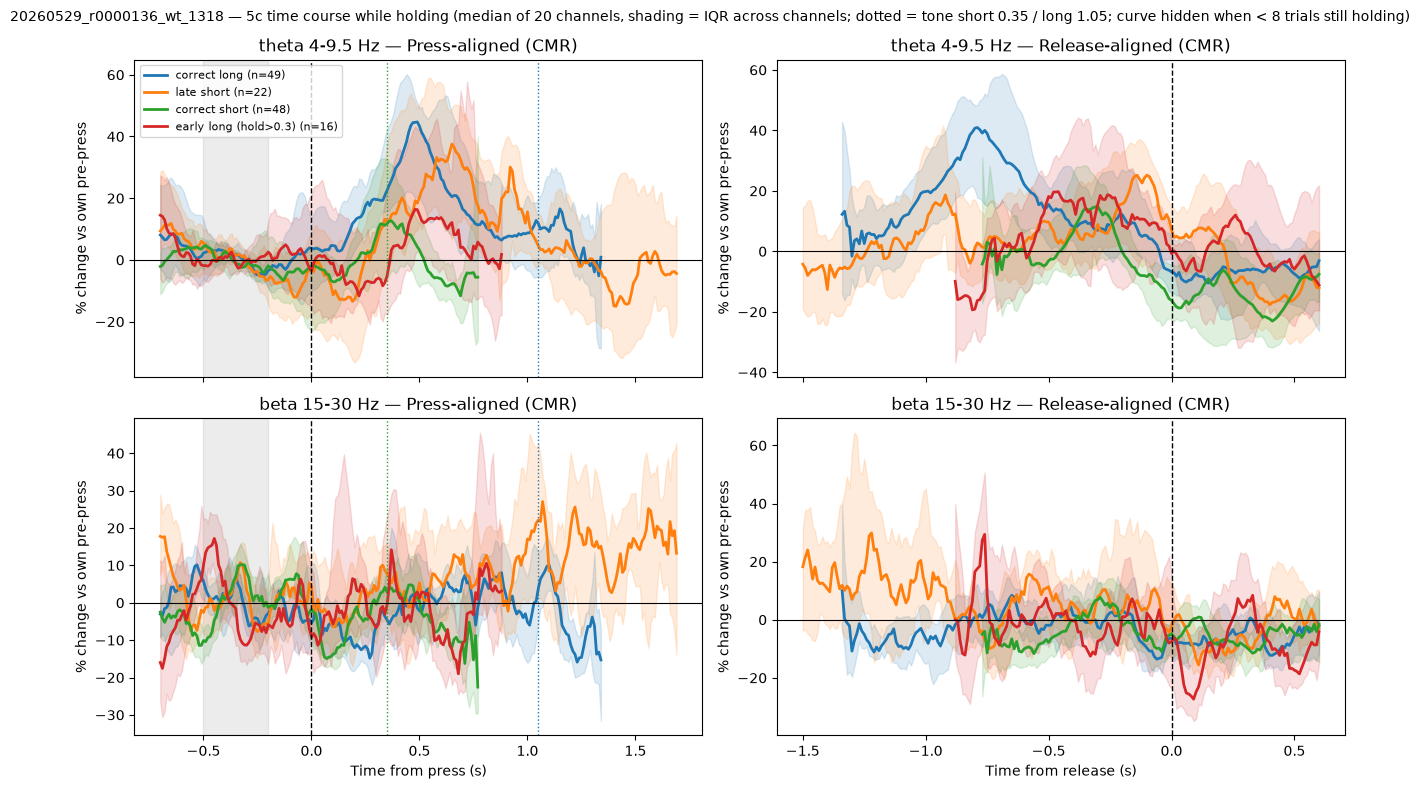

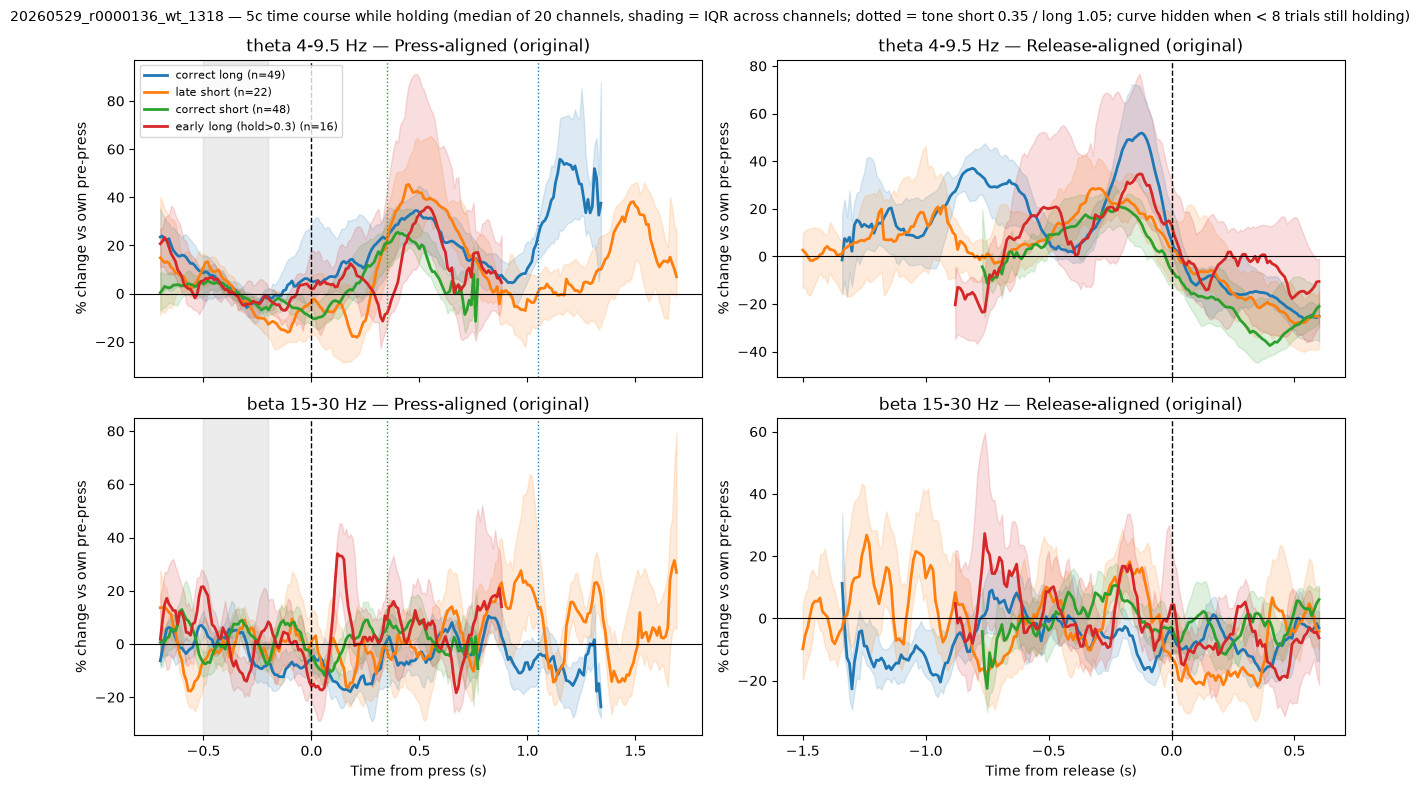

In [15]:
# %%
# ── 5c.1 compute curves (both references, 20 channels) ──
import io, contextlib, pickle, warnings
warnings.filterwarnings("ignore", message="All-NaN slice|Mean of empty slice")   # time points after every release
C5_BANDS = {"theta 4-9.5 Hz": (4, 9.5), "beta 15-30 Hz": (15, 30)}
C5_PRE   = (-0.5, -0.2)
C5_KEEP  = {"Press": (-0.7, 2.0), "Release": (-1.5, 0.6)}
C5_CONDS = {"correct long":          groups[("correct", "long")],
            "late short":            groups[("late", "short")],
            "correct short":         groups[("correct", "short")],
            "early long (hold>0.3)": groups[("early", "long-filtered")]}
C5_DIR = os.path.join(OUT_DIR, "5c_timecourse")
os.makedirs(C5_DIR, exist_ok=True)

c5_trials = pd.concat(C5_CONDS.values()); c5_trials = c5_trials[~c5_trials.index.duplicated()]
c5_hold = (c5_trials["release"] - c5_trials["press"])
print("trials per condition:", {k: len(v) for k, v in C5_CONDS.items()}, "| union:", len(c5_trials))

c5 = {}                                   # c5[ref][align][band][cond] -> (channels, times) % change
c5_times = {}
for ref in ["CMR", "original"]:
    rec = recordings[ref]
    per_ch = {al: {b: {c: [] for c in C5_CONDS} for b in C5_BANDS} for al in C5_KEEP}
    for i, ch in enumerate(selected_df["channel_id"]):
        with contextlib.redirect_stdout(io.StringIO()):
            pw = {al: tfs.extract_single_trial_power(rec, c5_trials, ch, EVENTS[al], CONFIG["band_settings"],
                                                      CONFIG["tmin"], CONFIG["tmax"], fs,
                                                      keep_window=C5_KEEP[al], decim=DECIM)
                  for al in C5_KEEP}
        pP, tP, freqs, kP = pw["Press"]
        base = np.log10(pP[:, :, (tP >= C5_PRE[0]) & (tP <= C5_PRE[1])]).mean(axis=2)   # mean LOG power, own pre-press
        base = pd.DataFrame(base, index=kP)
        for al in C5_KEEP:
            p, t, _, kept = pw[al]
            c5_times[al] = t
            ok = [k for k in kept if k in base.index]
            idx = [kept.index(k) for k in ok]
            lr = np.log10(p[idx]) - base.loc[ok].values[:, :, None]                  # (trials, freqs, times), 0 = own pre-press
            h = c5_hold.loc[ok].values[:, None]
            on_lever = (t[None, :] <= h) if al == "Press" else (t[None, :] >= -h)   # only while holding
            for b, (lo, hi) in C5_BANDS.items():
                bl = lr[:, (freqs >= lo) & (freqs <= hi), :].mean(axis=1)            # (trials, times)
                bl = np.where(on_lever, bl, np.nan)
                for c, ctr in C5_CONDS.items():
                    m = np.isin(ok, ctr.index)
                    with np.errstate(invalid="ignore"):
                        per_ch[al][b][c].append(100 * (10 ** np.nanmean(bl[m], axis=0) - 1))
        print(f"[{ref}] {i + 1}/{len(selected_df)} {ch}", flush=True)
    c5[ref] = {al: {b: {c: np.array(v) for c, v in d.items()} for b, d in bd.items()} for al, bd in per_ch.items()}

# trials still on the lever at each time point (same for all channels)
c5_n = {al: {c: [int(((c5_times[al] <= h) if al == "Press" else (c5_times[al] >= -h)).sum())
                 for h in (ctr["release"] - ctr["press"])] for c, ctr in C5_CONDS.items()} for al in C5_KEEP}
with open(os.path.join(C5_DIR, "5c_curves.pkl"), "wb") as f:
    pickle.dump({"c5": c5, "times": c5_times, "conds": list(C5_CONDS), "bands": C5_BANDS}, f)
print("saved:", os.path.join(C5_DIR, "5c_curves.pkl"))

# %%
# ── 5c.2 figure per reference: rows = bands, columns = Press / Release; median over 20 channels ──
C5_COLORS = {"correct long": "tab:blue", "late short": "tab:orange",
             "correct short": "tab:green", "early long (hold>0.3)": "tab:red"}
C5_MIN_TRIALS = 8                                         # hide a curve where fewer trials are still holding
for ref in c5:
    fig, axes = plt.subplots(len(C5_BANDS), 2, figsize=(13, 4 * len(C5_BANDS)), sharex="col")
    for r, b in enumerate(C5_BANDS):
        for col, al in enumerate(["Press", "Release"]):
            ax, t = axes[r, col], c5_times[al]
            for c in C5_CONDS:
                M = c5[ref][al][b][c]                                     # (channels, times)
                n_on = np.array([sum(((tt <= h) if al == "Press" else (tt >= -h))
                                     for h in (C5_CONDS[c]["release"] - C5_CONDS[c]["press"])) for tt in t])
                with np.errstate(invalid="ignore"):
                    med = np.nanmedian(M, axis=0)
                    q1, q3 = np.nanpercentile(M, 25, axis=0), np.nanpercentile(M, 75, axis=0)
                show = n_on >= C5_MIN_TRIALS
                ax.plot(t[show], med[show], color=C5_COLORS[c], lw=2, label=f"{c} (n={len(C5_CONDS[c])})")
                ax.fill_between(t[show], q1[show], q3[show], color=C5_COLORS[c], alpha=0.15)
            ax.axhline(0, color="k", lw=0.8)
            ax.axvline(0, color="k", ls="--", lw=1)
            if al == "Press":
                ax.axvspan(*C5_PRE, color="grey", alpha=0.15)
                ax.axvline(0.35, color="tab:green", ls=":", lw=1); ax.axvline(1.05, color="tab:blue", ls=":", lw=1)
            ax.set_title(f"{b} — {al}-aligned ({ref})")
            ax.set_ylabel("% change vs own pre-press")
            if r == len(C5_BANDS) - 1:
                ax.set_xlabel(f"Time from {al.lower()} (s)")
    axes[0, 0].legend(fontsize=8, loc="upper left")
    fig.suptitle(f"{SESSION} — 5c time course while holding (median of 20 channels, shading = IQR across channels; "
                 f"dotted = tone short 0.35 / long 1.05; curve hidden when < {C5_MIN_TRIALS} trials still holding)",
                 fontsize=10)
    fig.tight_layout()
    fig.savefig(os.path.join(C5_DIR, f"5c_timecourse_{ref}.png"), dpi=150, bbox_inches="tight")
    plt.show()

trials per condition: {'correct long': 49, 'correct short': 48, 'late short': 22, 'early long (hold>0.3)': 16} | union: 135
1/20 imec0.ap#AP15
2/20 imec0.ap#AP30
3/20 imec0.ap#AP49
4/20 imec0.ap#AP66
5/20 imec0.ap#AP91
6/20 imec0.ap#AP109
7/20 imec0.ap#AP120
8/20 imec0.ap#AP156
9/20 imec0.ap#AP159
10/20 imec0.ap#AP205
11/20 imec0.ap#AP232
12/20 imec0.ap#AP240
13/20 imec0.ap#AP241
14/20 imec0.ap#AP257
15/20 imec0.ap#AP282
16/20 imec0.ap#AP289
17/20 imec0.ap#AP324
18/20 imec0.ap#AP335
19/20 imec0.ap#AP353
20/20 imec0.ap#AP372


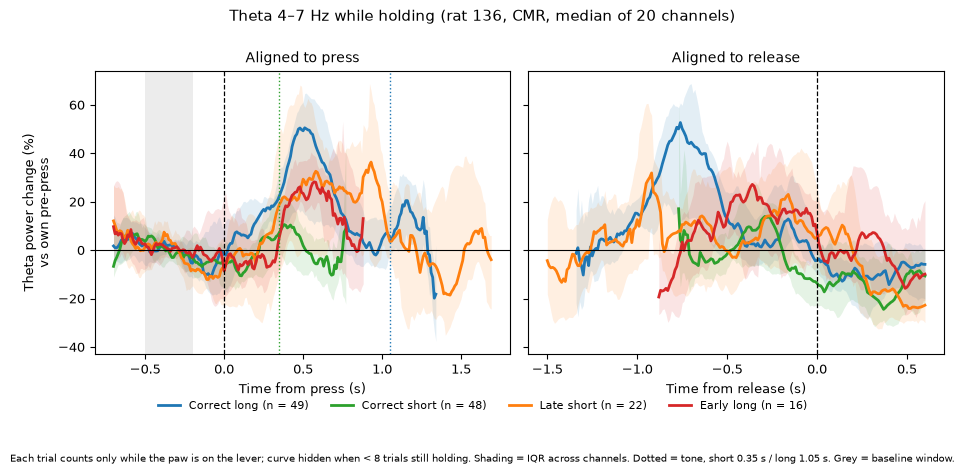

saved in C:\Users\ar687\Desktop


In [14]:
# %%
# ── 5c theta 4-7 Hz, CMR only: compute + one clean figure (needs cells 0, 1, 2 run) ──
import os, io, contextlib, pickle, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore", message="All-NaN slice|Mean of empty slice")
REF, BAND = "CMR", (4, 7)
C5_PRE  = (-0.5, -0.2)
C5_KEEP = {"Press": (-0.7, 2.0), "Release": (-1.5, 0.6)}
C5_CONDS = {"correct long":          groups[("correct", "long")],
            "correct short":         groups[("correct", "short")],
            "late short":            groups[("late", "short")],
            "early long (hold>0.3)": groups[("early", "long-filtered")]}
C5_DIR = os.path.join(OUT_DIR, "5c_timecourse"); os.makedirs(C5_DIR, exist_ok=True)

c5_trials = pd.concat(C5_CONDS.values()); c5_trials = c5_trials[~c5_trials.index.duplicated()]
c5_hold = (c5_trials["release"] - c5_trials["press"])
print("trials per condition:", {k: len(v) for k, v in C5_CONDS.items()}, "| union:", len(c5_trials))

rec = recordings[REF]
curves = {al: {c: [] for c in C5_CONDS} for al in C5_KEEP}
times = {}
for i, ch in enumerate(selected_df["channel_id"]):
    with contextlib.redirect_stdout(io.StringIO()):
        pw = {al: tfs.extract_single_trial_power(rec, c5_trials, ch, EVENTS[al], CONFIG["band_settings"],
                                                  CONFIG["tmin"], CONFIG["tmax"], fs,
                                                  keep_window=C5_KEEP[al], decim=DECIM)
              for al in C5_KEEP}
    pP, tP, freqs, kP = pw["Press"]
    base = np.log10(pP[:, :, (tP >= C5_PRE[0]) & (tP <= C5_PRE[1])]).mean(axis=2)     # own pre-press, log power
    base = pd.DataFrame(base, index=kP)
    for al in C5_KEEP:
        p, t, _, kept = pw[al]
        times[al] = t
        ok = [k for k in kept if k in base.index]
        idx = [kept.index(k) for k in ok]
        lr = np.log10(p[idx]) - base.loc[ok].values[:, :, None]
        h = c5_hold.loc[ok].values[:, None]
        on_lever = (t[None, :] <= h) if al == "Press" else (t[None, :] >= -h)           # only while holding
        bl = lr[:, (freqs >= BAND[0]) & (freqs <= BAND[1]), :].mean(axis=1)
        bl = np.where(on_lever, bl, np.nan)
        for c, ctr in C5_CONDS.items():
            m = np.isin(ok, ctr.index)
            with np.errstate(invalid="ignore"):
                curves[al][c].append(100 * (10 ** np.nanmean(bl[m], axis=0) - 1))
    print(f"{i + 1}/{len(selected_df)} {ch}", flush=True)
curves = {al: {c: np.array(v) for c, v in d.items()} for al, d in curves.items()}      # (channels, times)
with open(os.path.join(C5_DIR, "5c_curves_theta47_CMR.pkl"), "wb") as f:
    pickle.dump({"curves": curves, "times": times, "conds": list(C5_CONDS), "band": BAND}, f)

# ── figure: theta 4-7 Hz, Press-aligned and Release-aligned, four conditions ──
COL  = {"correct long": "tab:blue", "correct short": "tab:green", "late short": "tab:orange", "early long (hold>0.3)": "tab:red"}
NAME = {"correct long": "Correct long", "correct short": "Correct short", "late short": "Late short", "early long (hold>0.3)": "Early long"}
MIN_TR = 8                                              # hide a curve where fewer trials are still holding
plt.rcParams.update({"font.size": 9, "axes.linewidth": 0.8})
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4), sharey=True)
for ax, al in zip(axes, ["Press", "Release"]):
    t = times[al]
    for c, ctr in C5_CONDS.items():
        hh = (ctr["release"] - ctr["press"]).values[:, None]
        n_on = ((t[None, :] <= hh) if al == "Press" else (t[None, :] >= -hh)).sum(axis=0)
        M = curves[al][c]
        with np.errstate(invalid="ignore"):
            med = np.nanmedian(M, axis=0)
            q1, q3 = np.nanpercentile(M, 25, axis=0), np.nanpercentile(M, 75, axis=0)
        s = n_on >= MIN_TR
        ax.plot(t[s], med[s], color=COL[c], lw=2, label=f"{NAME[c]} (n = {len(ctr)})")
        ax.fill_between(t[s], q1[s], q3[s], color=COL[c], alpha=0.12, lw=0)
    ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color="k", ls="--", lw=0.9)
    if al == "Press":
        ax.axvspan(*C5_PRE, color="grey", alpha=0.15, lw=0)
        ax.axvline(0.35, color="tab:green", ls=":", lw=1); ax.axvline(1.05, color="tab:blue", ls=":", lw=1)
    ax.set_xlabel(f"Time from {al.lower()} (s)")
axes[0].set_ylabel("Theta power change (%)\nvs own pre-press")
axes[0].set_title("Aligned to press", fontsize=10); axes[1].set_title("Aligned to release", fontsize=10)
fig.suptitle(f"Theta 4–7 Hz while holding (rat 136, CMR, median of {len(selected_df)} channels)", fontsize=10.5, y=1.0)
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=4, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.03))
fig.text(0.5, -0.11, "Each trial counts only while the paw is on the lever; curve hidden when < 8 trials still holding. "
         "Shading = IQR across channels. Dotted = tone, short 0.35 s / long 1.05 s. Grey = baseline window.",
         ha="center", va="top", fontsize=7)
fig.tight_layout()
desk = os.path.join(os.path.expanduser("~"), "Desktop")
if not os.path.isdir(desk): desk = os.path.join(os.path.expanduser("~"), "OneDrive", "Desktop")
fig.savefig(os.path.join(desk, "pilot_theta_timecourse.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(desk, "pilot_theta_timecourse_white.png"), dpi=600, facecolor="white", bbox_inches="tight")
fig.savefig(os.path.join(desk, "pilot_theta_timecourse_transparent.png"), dpi=600, transparent=True, bbox_inches="tight")
plt.show()
print("saved in", desk)


 <div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

 ## 6. Q1 — waiting vs acting: correct long vs correct short (Press-aligned, 21 channels)
 - Both trial types are identical until the short tone (0.35 s); the rat cannot know the type (random).
 - **Main window**: 0.35 s → `q1_end` (long = still waiting, short = tone heard, about to release).
   `q1_end` = longest end that ≥ 90 % of the trials of BOTH groups still cover (set by correct-short holds).
 - **Control window**: 0.00 → 0.35 s (same situation in both groups → expect no difference).
 - Test: cluster permutation per channel (Welch t, label shuffle, 5000 permutations), on log10(power / common
   pre-press baseline of all kept trials); raw cluster p (no FDR in the pilot). Both references.
 </div>

In [11]:
# ── 6.1 settings: groups, window end ──
import json
Q1_A, Q1_B = ("correct", "long"), ("correct", "short")
Q1_LABELS  = ("long", "short")                       # directions: "long > short" / "short > long"
Q1_START   = 0.35
q1_end     = tfs.auto_window_end(groups[Q1_A], groups[Q1_B], "Press", keep=0.9)
Q1_WINDOWS = {"main": (Q1_START, q1_end), "control_0-0.35": (0.0, Q1_START)}
Q1_CHANNELS = list(selected_df["channel_id"])
REFS_Q1    = {"CMR": recordings["CMR"], "original": recordings["original"]}
Q1_DIR     = os.path.join(OUT_DIR, "Q1_correct_long_vs_short")
os.makedirs(Q1_DIR, exist_ok=True)

# checks: CONFIG keys used inside tfs.run_two_group
for k in ("events", "baseline_window", "band_settings", "tmin", "tmax"):
    assert k in CONFIG, f"CONFIG has no key '{k}'"
print("CONFIG events:", CONFIG["events"], "| baseline:", CONFIG["baseline_window"],
      "| tmin/tmax:", CONFIG["tmin"], CONFIG["tmax"])
print(f"correct long n={len(groups[Q1_A])} | correct short n={len(groups[Q1_B])} | "
      f"all trials (baseline) n={len(all_trials)} | channels {len(Q1_CHANNELS)} | refs {list(REFS_Q1)}")
hold_s = (groups[Q1_B]["release"] - groups[Q1_B]["press"])
print(f"correct short hold: q10 {hold_s.quantile(0.1):.3f} | median {hold_s.median():.3f} s")
print("Q1 windows:", Q1_WINDOWS)
if q1_end - Q1_START < 0.1:
    print("WARNING: main window shorter than 0.1 s - tell Claude before running 6.2")

with open(os.path.join(Q1_DIR, "q1_settings.json"), "w") as f:
    json.dump({"session": SESSION, "A": Q1_A, "B": Q1_B, "windows": Q1_WINDOWS,
               "channels": Q1_CHANNELS, "refs": list(REFS_Q1), "n_perm": N_PERMUTATIONS,
               "seed": SEED, "decim": DECIM, "nA": len(groups[Q1_A]), "nB": len(groups[Q1_B])},
              f, indent=2)

# %%
# ── 6.2 run the tests (long: leave it running; a stopped run continues where it stopped) ──
for name, win in Q1_WINDOWS.items():
    print(f"\n===== Q1 {name}: Press {win[0]:.2f} -> {win[1]:.2f} s =====")
    tfs.run_two_group(REFS_Q1, groups, all_trials, Q1_A, Q1_B, Q1_LABELS, Q1_CHANNELS, CONFIG, fs,
                      tests={"Press": {"window": win}}, stat_bands=STAT_BANDS,
                      out_dir=os.path.join(Q1_DIR, name), n_perm=N_PERMUTATIONS, seed=SEED, decim=DECIM)
print("\nQ1 done:", Q1_DIR)

# %%
# ── 6.3 summary: significant channels per band and direction (raw cluster p < 0.05) + cluster list ──
pd.set_option("display.width", 250)
q1_rows = []
for name in Q1_WINDOWS:
    wdir = os.path.join(Q1_DIR, name)
    summ = tfs.two_group_tables(wdir, list(REFS_Q1), ["Press"], probe_df, Q1_LABELS, STAT_BANDS)
    print(f"\n===== Q1 {name} {Q1_WINDOWS[name]} — number of channels with a significant cluster =====")
    print(summ["Press"].to_string())
    for ref in REFS_Q1:
        res = tfs.load_two_group(wdir, ref, Q1_CHANNELS)
        for ch, rr in res.items():
            r = rr["Press"]
            if not r["tested"]:
                q1_rows.append({"window": name, "ref": ref, "channel": ch, "tested": False,
                                "nA": r["nA"], "nB": r["nB"]})
                continue
            for c in r["clusters"]:
                if c["significant"]:
                    q1_rows.append({"window": name, "ref": ref, "channel": ch, "tested": True,
                                    "nA": r["nA"], "nB": r["nB"], **c})

q1_sum = pd.DataFrame(q1_rows)
if len(q1_sum):
    yy = probe_df.set_index("channel_id")["y"]
    q1_sum.insert(3, "y (um)", q1_sum["channel"].map(yy))
    q1_sum = q1_sum.sort_values(["window", "ref", "y (um)"]).reset_index(drop=True)
q1_sum.to_csv(os.path.join(Q1_DIR, "q1_summary.csv"), index=False)
print("\nsignificant clusters (raw cluster p < 0.05):")
print(q1_sum.to_string(index=False) if len(q1_sum) else "none")
print("saved:", os.path.join(Q1_DIR, "q1_summary.csv"))

CONFIG events: {'Press': 'press_np_s', 'Tone': 'tone_np_s', 'Release': 'release_np_s'} | baseline: (-0.5, -0.2) | tmin/tmax: -3 5
correct long n=49 | correct short n=48 | all trials (baseline) n=142 | channels 20 | refs ['CMR', 'original']
correct short hold: q10 0.630 | median 0.710 s
Q1 windows: {'main': (0.35, 0.6), 'control_0-0.35': (0.0, 0.35)}

===== Q1 main: Press 0.35 -> 0.60 s =====
[CMR] 1/20 imec0.ap#AP15 | Press: nA=49 nB=46 p_min=0.5043
[CMR] 2/20 imec0.ap#AP30 | Press: nA=49 nB=46 p_min=0.7986
[CMR] 3/20 imec0.ap#AP49 | Press: nA=49 nB=46 p_min=0.3379
[CMR] 4/20 imec0.ap#AP66 | Press: nA=49 nB=46 p_min=0.2096
[CMR] 5/20 imec0.ap#AP91 | Press: nA=49 nB=46 p_min=0.3107
[CMR] 6/20 imec0.ap#AP109 | Press: nA=49 nB=46 p_min=0.0592
[CMR] 7/20 imec0.ap#AP120 | Press: nA=49 nB=46 p_min=0.9796
[CMR] 8/20 imec0.ap#AP156 | Press: nA=49 nB=46 p_min=0.1408
[CMR] 9/20 imec0.ap#AP159 | Press: nA=49 nB=46 p_min=0.6931
[CMR] 10/20 imec0.ap#AP205 | Press: nA=49 nB=46 p_min=0.0384
[CMR] 11/